# A. Model considering only the main sequence (only the disease we are interested in studying)

### 1. Sequnce importing

In [2]:
import pandas as pd
df_main = pd.read_csv('sequence_main_final.csv')

In [3]:
df_main.head()

,f.eid,age_in_days_since_born,event_id,token,disease_name
0,1000191.0,15223,9,9,Diabetes Mellitus
1,1000191.0,19206,16,16,Hypertension
2,1000191.0,19217,11,11,Dyslipidemias
3,1000239.0,20698,11,11,Dyslipidemias
4,1000239.0,20698,16,16,Hypertension


In [4]:
sequences = df_main.groupby('f.eid')['disease_name'].apply(list).tolist()
print("Unique patients:", df_main['f.eid'].nunique())

Unique patients: 113973


In [5]:
word_sequences = [[word.lower() for phrase in seq for word in phrase.replace(',', ' ').split()] for seq in sequences]
all_words = [word for seq in word_sequences for word in seq]
unique_words = sorted(set(all_words))

In [6]:
len(word_sequences)

113973

In [7]:
word_sequences

[['diabetes', 'mellitus', 'hypertension', 'dyslipidemias'],
 ['dyslipidemias',
  'hypertension',
  'cerebrovascular',
  'disorders',
  'coronary',
  'disease',
  'peripheral',
  'vascular',
  'diseases',
  'coronary',
  'disease',
  'atrial',
  'fibrillation',
  'cerebrovascular',
  'disorders'],
 ['dyslipidemias', 'diabetes', 'mellitus', 'hypertension'],
 ['hypertension', 'dyslipidemias', 'pulmonary', 'embolism'],
 ['atrial',
  'fibrillation',
  'kidney',
  'failure',
  'chronic',
  'endstage',
  'hypertension',
  'kidney',
  'diseases',
  'chronic',
  'stage',
  '5',
  'diabetes',
  'mellitus',
  'acute',
  'kidney',
  'injury',
  'acute',
  'kidney',
  'injury',
  'acute',
  'kidney',
  'injury',
  'coronary',
  'disease',
  'dyslipidemias',
  'coronary',
  'disease'],
 ['coronary',
  'disease',
  'heart',
  'failure',
  'coronary',
  'disease',
  'hypertension',
  'coronary',
  'disease',
  'dyslipidemias',
  'coronary',
  'disease'],
 ['hypertension',
  'acute',
  'kidney',
  'inj

### 2. Model definition and training

In [23]:
from gensim.models import Word2Vec
import matplotlib.pyplot as plt
import time
from gensim.models import FastText

# Load existing BioWordVec model
model_main = FastText.load("./pubmed_mesh_test")

In [24]:
words = list(model_main.wv.key_to_index)
missing_words = [w for w in unique_words if w not in words]
print(f" Missing words in pretrained model: {missing_words}")

# Update vocabulary with new sequences (if needed)
model_main.build_vocab(word_sequences, update=True)

# Fine-tune the model
epochs = 4  # You can increase this if needed

start_time = time.time()

for epoch in range(epochs):
    model_main.train(
        word_sequences,
        total_examples=len(word_sequences),
        epochs=1
    )
    print(f"Epoch {epoch + 1} completed.")

end_time = time.time()
print(f"\n Fine-tuning completed in {end_time - start_time:.2f} seconds")

# Save the fine-tuned model
model_main.save("./pubmed_mesh_finetuned_main")
print(" Fine-tuned model saved to './pubmed_mesh_finetuned_main'")

 Missing words in pretrained model: ['endstage']
Epoch 1 completed.
Epoch 2 completed.
Epoch 3 completed.
Epoch 4 completed.

 Fine-tuning completed in 18.36 seconds
 Fine-tuned model saved to './pubmed_mesh_finetuned_main'


In [25]:
from gensim.models import FastText
from scipy.spatial.distance import cosine
import numpy as np
import pandas as pd

# Load original and fine-tuned models
original_model_main = FastText.load("./pubmed_mesh_test")
updated_model_main = FastText.load("./pubmed_mesh_finetuned_main")


In [26]:
# Define the epoch to fine-tuned on based on the mean cosing beeing over 75% for the words present in our sequences
target_words = list(set(all_words))

comparison = []

for word in target_words:
    if word in original_model_main.wv and word in updated_model_main.wv:
        original_vec = original_model_main.wv[word]
        updated_vec = updated_model_main.wv[word]
        similarity = 1 - cosine(original_vec, updated_vec)
        comparison.append((word, similarity))
    elif word in updated_model.wv:
        comparison.append((word, "Added during fine-tuning)"))
    else:
        comparison.append((word, "Not in fine-tuned model"))

# Display results
df_compare = pd.DataFrame(comparison, columns=["Word", "Cosine Similarity"])
numeric_similarities = pd.to_numeric(df_compare["Cosine Similarity"], errors='coerce')
mean_similarity = numeric_similarities.mean()
print(f"Mean cosine similarity (original vs fine-tuned): {mean_similarity:.4f}")
#### Epochs defined so that the cosine similarity of the word embedding between original and fine-tuned is over 70%

Mean cosine similarity (original vs fine-tuned): 0.7015


### 3. Embedding extraction and similarity computation

In [8]:
from gensim.models import FastText
from scipy.spatial.distance import cosine
import numpy as np
import pandas as pd
updated_model_main = FastText.load("./pubmed_mesh_finetuned_main")

In [9]:
from gensim.models import FastText
import numpy as np

# Flatten and get unique phrases
unique_phrases = set(phrase for seq in sequences for phrase in seq)

# Create a dict to hold phrase-level embeddings
phrase_embeddings_main = {}

for phrase in unique_phrases:
    words = phrase.replace("-", " ").lower().split()
    word_vectors = []

    for word in words:
        if word in updated_model_main.wv:
            word_vectors.append(updated_model_main.wv[word])
        else:
            print(f" Word '{word}' not in vocabulary, skipped.")

    if word_vectors:
        # Compute the average embedding
        phrase_vector = np.mean(word_vectors, axis=0)
        phrase_embeddings_main[phrase] = phrase_vector
    else:
        print(f" No valid embeddings found for phrase: '{phrase}'")

print(f"Computed embeddings for {len(phrase_embeddings_main)} phrases.")

Computed embeddings for 24 phrases.


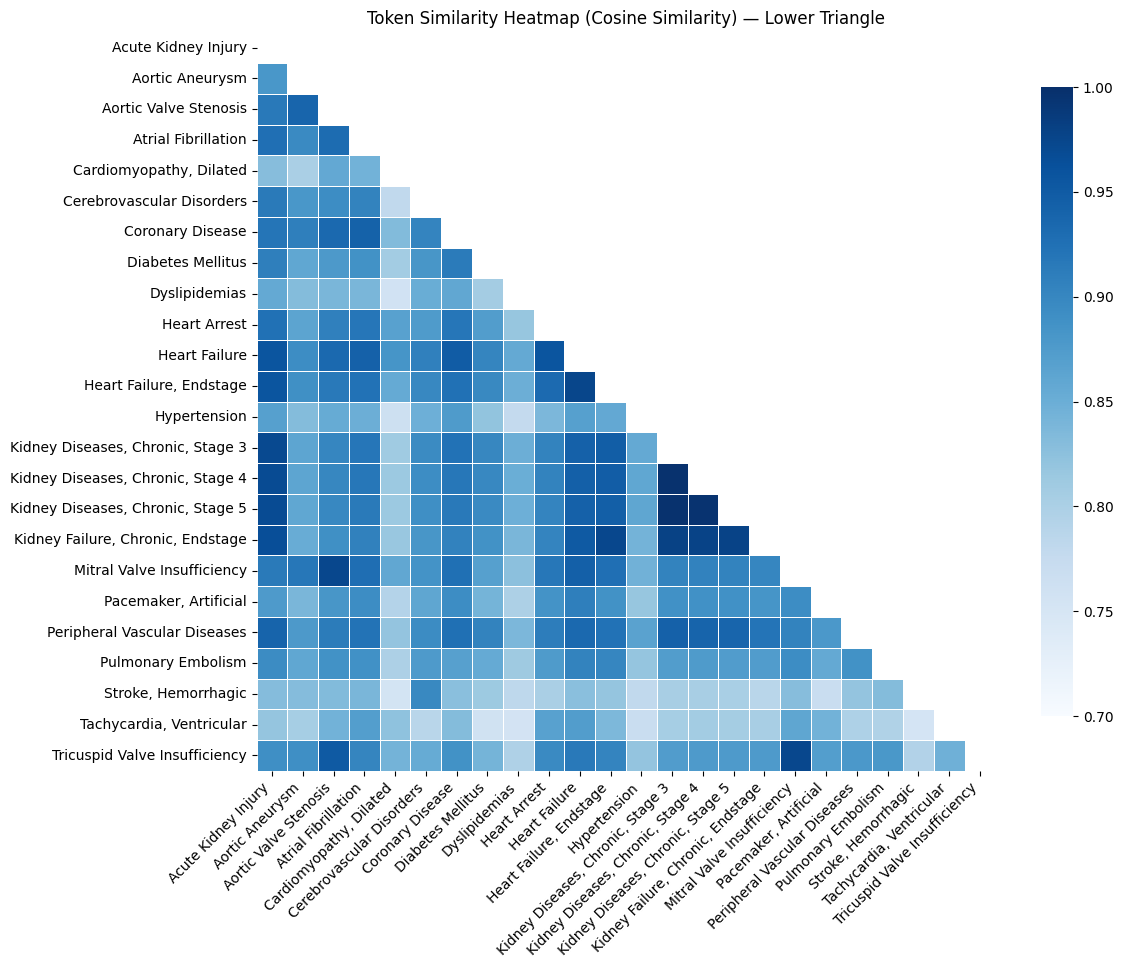

In [10]:
# Get sorted list of phrases for consistent order
phrases = sorted(phrase_embeddings_main.keys())

# Initialize an empty similarity matrix
similarity_matrix_main = np.zeros((len(phrases), len(phrases)))

# Fill the matrix
for i, phrase_i in enumerate(phrases):
    for j, phrase_j in enumerate(phrases):
        vec_i = phrase_embeddings_main[phrase_i]
        vec_j = phrase_embeddings_main[phrase_j]
        similarity = 1 - cosine(vec_i, vec_j)
        similarity_matrix_main[i, j] = similarity

# Convert to pandas DataFrame for readability
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


similarity_df_main = pd.DataFrame(similarity_matrix_main, index=phrases, columns=phrases)

# Mask: hide upper triangle + diagonal -> show only lower triangle (excluding diagonal)
mask = np.triu(np.ones(similarity_df_main.shape, dtype=bool), k=0)

plt.figure(figsize=(12, 10))
sns.heatmap(
    similarity_df_main,
    mask=mask,
    cmap="Blues",          # light -> dark blue (one direction)
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=0.7, vmax=1         # good for cosine similarity; remove if not in [0,1]
)

plt.title("Token Similarity Heatmap (Cosine Similarity) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_heatmap_main.svg", format="svg")
plt.show()

### 4. Network construction and visualization

In [11]:
import networkx as nx
def weighted_graph_construction(correlation_df, threshold):
    """
    Construct the weighted graph based on a correlation matrix.
 
    Parameters:
    - correlation_matrix: numpy array, input correlation matrix
    - threshold: float, correlation threshold for creating edges in the graph
 
    Returns:
    - G: graph, output weighted graph
    """
    # Create a graph from the correlation matrix with weights above the threshold
    correlation_matrix = np.absolute(np.array(correlation_df))
    G = nx.DiGraph()
    num_nodes = correlation_matrix.shape[0]
    prot_names = correlation_df.columns
    G.add_nodes_from(prot_names)
 
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            if np.abs(correlation_matrix[i, j]) > threshold:
                G.add_edge(prot_names[i], prot_names[j], weight=correlation_matrix[i, j])
    print(f'Proportion of #edges: {len(G.edges)/num_nodes**2}')
    G = G.to_undirected()
    return G
 
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib.cm as cm
import matplotlib.colors as mcolors

def plot_weighted_graph_colored(G, cmap_name="coolwarm"):
    """
    Plot a weighted graph with edge colors and transparency based on weight.
    Higher weights = more intense color + less transparency.

    Parameters:
    - G: NetworkX graph with 'weight' attributes on edges
    - cmap_name: Matplotlib colormap name
    """
    plt.figure(figsize=(16, 12))
    ax = plt.gca()
    pos = nx.circular_layout(G)

    # Extract edge weights
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    min_w, max_w = min(weights), max(weights)

    # Normalize weights
    norm = mcolors.Normalize(vmin=min_w, vmax=max_w)
    cmap = plt.colormaps[cmap_name]

    # Map weight to RGBA (color + alpha)
    edge_colors = []
    for w in weights:
        base_color = cmap(norm(w))
        alpha = 0.1 + 0.9 * norm(w)  # scale alpha from 0.1 (faint) to 1.0 (solid)
        edge_colors.append((base_color[0], base_color[1], base_color[2], alpha))

    # Draw graph
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color='lightgray')
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_color='black')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=2)

    # Add colorbar
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
    cbar.set_label("Similarity", fontsize=12)

    plt.title("Graph Colored by Edge Similarity", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("graph_similarity_plot_main.svg", format="svg")
    
    plt.show()



Proportion of #edges: 0.4791666666666667


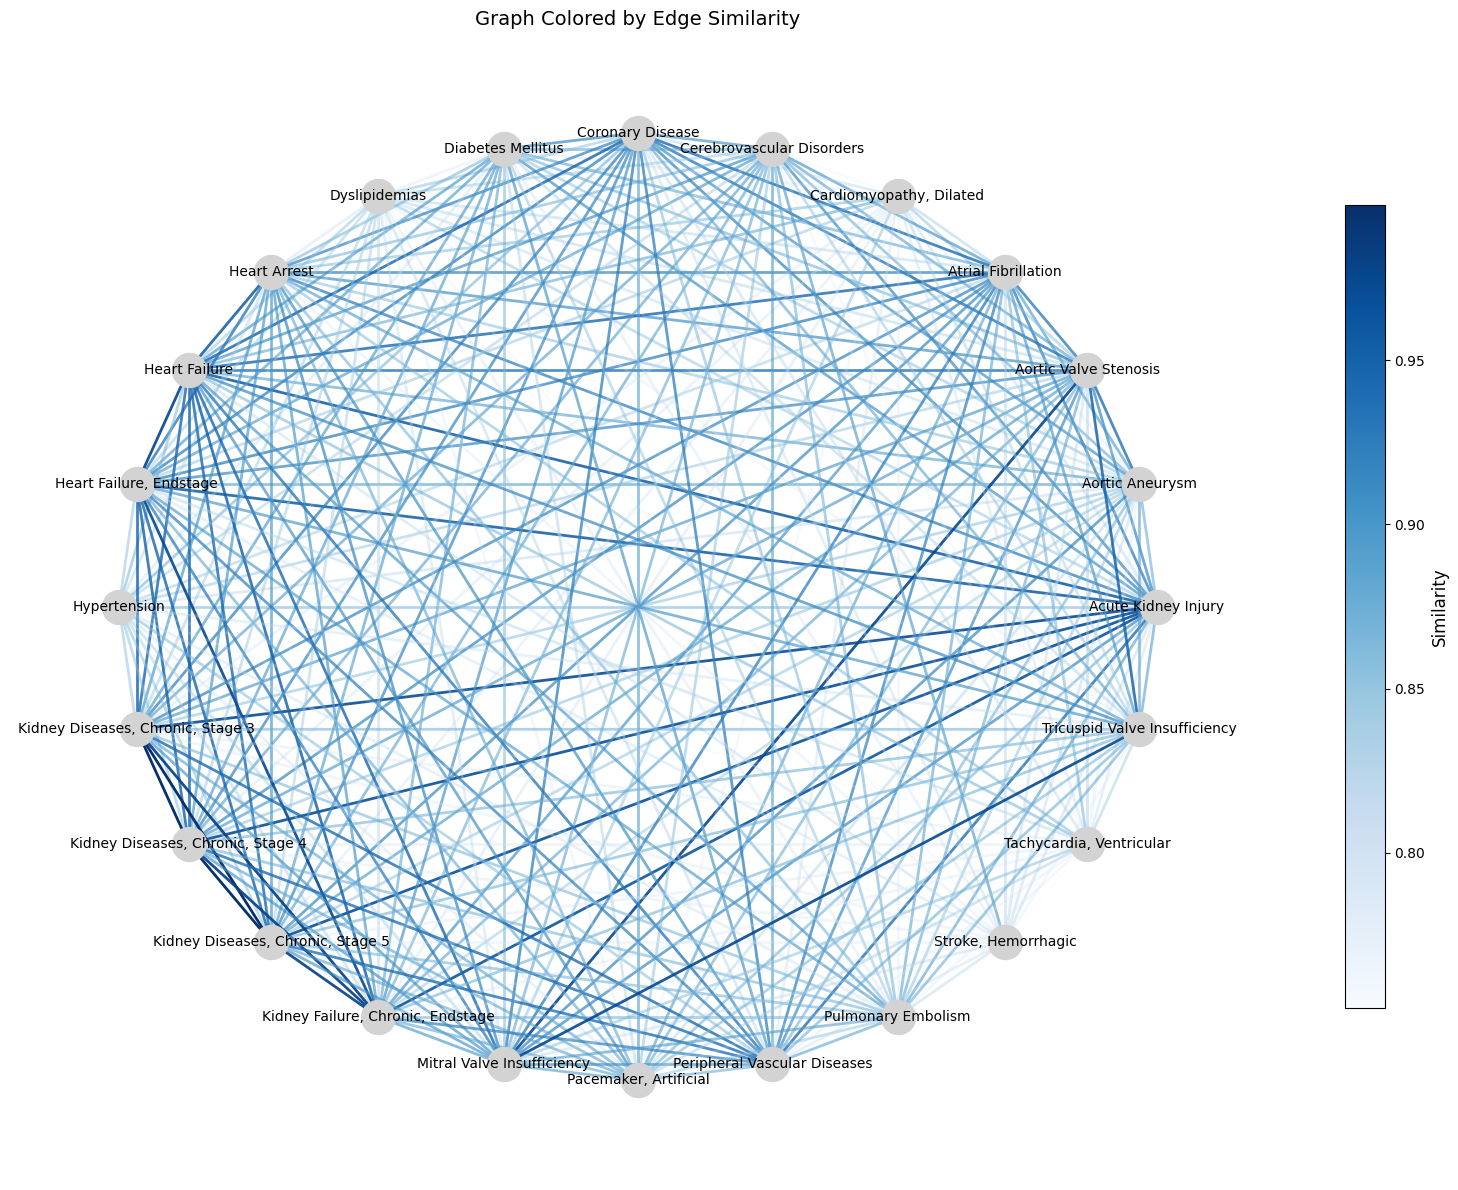

In [12]:
G = weighted_graph_construction(similarity_df_main, threshold=0.0)
plot_weighted_graph_colored(G, cmap_name="Blues")

# B. Model considering also risk modifiers ( main + parallel sequences)

### 1. Sequnce preprocessing 

In [13]:
import pandas as pd
df_main_par = pd.read_csv('sequence_main_parr_final.csv')

In [14]:
sequences = df_main_par.groupby('f.eid')['disease_name'].apply(list).tolist()
print("Unique patients:", df_main_par['f.eid'].nunique())

Unique patients: 113973


In [15]:
# Split the MeSH disease terms into single words to define a word sequence
word_sequences = [[word.lower() for phrase in seq for word in phrase.replace(',', ' ').split()] for seq in sequences]
all_words = [word for seq in word_sequences for word in seq]
unique_words = sorted(set(all_words))

In [16]:
word_sequences

[['male',
  'ethnic',
  'white',
  'history',
  'mother',
  'diabetes',
  'history',
  'mother',
  'stroke',
  'history',
  'father',
  'diabetes',
  'history',
  'father',
  'heart',
  'diseases',
  'history',
  'siblings',
  'heart',
  'diseases',
  'history',
  'siblings',
  'stroke',
  'body',
  'mass',
  'index',
  'high',
  'socioeconomic',
  'factors',
  'middle',
  'employment',
  'active',
  'educational',
  'status',
  'high',
  'marital',
  'status',
  'social',
  'environment',
  'smoking',
  'no',
  'blood',
  'pressure',
  'high',
  'hemoglobins',
  'anemia',
  'kidney',
  'diseases',
  'chronic',
  'stage',
  '1',
  'blood',
  'pressure',
  'high',
  'diabetes',
  'mellitus',
  'hypothyroidism',
  'hypertension',
  'dyslipidemias'],
 ['female',
  'ethnic',
  'white',
  'history',
  'mother',
  'heart',
  'diseases',
  'history',
  'mother',
  'stroke',
  'history',
  'father',
  'stroke',
  'history',
  'siblings',
  'heart',
  'diseases',
  'history',
  'siblings',
  's

### 2. Model definition and training

In [52]:
from gensim.models import Word2Vec
import matplotlib.pyplot as plt
import time
from gensim.models import FastText

# Load existing FastText model
model_main_par = FastText.load("./pubmed_mesh_test")

In [53]:
words = list(model_main_par.wv.key_to_index)
missing_words = [w for w in unique_words if w not in words]
print(f" Missing words in pretrained model: {missing_words}")

# Update vocabulary with new sequences (if needed)
model_main_par.build_vocab(word_sequences, update=True)

# Fine-tune the model
epochs = 4  # You can increase this if needed

start_time = time.time()

for epoch in range(epochs):
    model_main_par.train(
        word_sequences,
        total_examples=len(word_sequences),
        epochs=1
    )
    print(f"Epoch {epoch + 1} completed.")

end_time = time.time()
print(f"\n Fine-tuning completed in {end_time - start_time:.2f} seconds")

# Save the fine-tuned model
model_main_par.save("./pubmed_mesh_finetuned_main_par")
print(" Fine-tuned model saved to './pubmed_mesh_finetuned_main_par'")

 Missing words in pretrained model: ['endstage']
Epoch 1 completed.
Epoch 2 completed.
Epoch 3 completed.
Epoch 4 completed.

 Fine-tuning completed in 156.60 seconds
 Fine-tuned model saved to './pubmed_mesh_finetuned_main_par'


In [54]:
from gensim.models import FastText
from scipy.spatial.distance import cosine
import numpy as np
import pandas as pd

# Load original and fine-tuned models
original_model_main_par = FastText.load("./pubmed_mesh_test")
updated_model_main_par = FastText.load("./pubmed_mesh_finetuned_main_par")

In [55]:
# This could be used to define the epoch to fine-tuned on based on the mean cosing beeing over 75% for the words present in our sequences.
# We choose to use the same number of epoch as the model based just n main sequences
target_words = list(set(all_words))

comparison = []

for word in target_words:
    if word in original_model_main_par.wv and word in updated_model_main_par.wv:
        original_vec = original_model_main_par.wv[word]
        updated_vec = updated_model_main_par.wv[word]
        similarity = 1 - cosine(original_vec, updated_vec)
        comparison.append((word, similarity))
    elif word in updated_model.wv:
        comparison.append((word, "Added during fine-tuning)"))
    else:
        comparison.append((word, "Not in fine-tuned model"))

# Display results
df_compare = pd.DataFrame(comparison, columns=["Word", "Cosine Similarity"])
numeric_similarities = pd.to_numeric(df_compare["Cosine Similarity"], errors='coerce')
mean_similarity = numeric_similarities.mean()
print(f"Mean cosine similarity (original vs fine-tuned): {mean_similarity:.4f}")
#### Epochs defined based on the benchmark

Mean cosine similarity (original vs fine-tuned): 0.4825


### 3. Embedding extraction and similarity computation

In [17]:
from gensim.models import FastText
from scipy.spatial.distance import cosine
import numpy as np
import pandas as pd
updated_model_main_par = FastText.load("./pubmed_mesh_finetuned_main_par")

In [18]:
from gensim.models import FastText
import numpy as np

# Flatten and get unique phrases
unique_phrases = set(phrase for seq in sequences for phrase in seq)

# Create a dict to hold phrase-level embeddings
phrase_embeddings_main_par = {}

for phrase in unique_phrases:
    words = phrase.replace("-", " ").lower().split()
    word_vectors = []

    for word in words:
        if word in updated_model_main_par.wv:
            word_vectors.append(updated_model_main_par.wv[word])
        else:
            print(f" Word '{word}' not in vocabulary, skipped.")

    if word_vectors:
        # Compute the average embedding
        phrase_vector = np.mean(word_vectors, axis=0)
        phrase_embeddings_main_par[phrase] = phrase_vector
    else:
        print(f" No valid embeddings found for phrase: '{phrase}'")

print(f"Computed embeddings for {len(phrase_embeddings_main_par)} phrases.")

Computed embeddings for 121 phrases.


In [19]:
embedding_df = pd.DataFrame(phrase_embeddings_main_par)

In [20]:
embedding_df = pd.DataFrame(phrase_embeddings_main_par)
print(embedding_df.shape)
print(embedding_df.head())
embedding_df.to_csv("phrase_embeddings_main_par_df.csv", index=False)

(200, 121)
   History, Siblings, Heart Diseases  Stroke, Hemorrhagic  \
0                          -0.066650            -0.365915   
1                          -0.134357            -0.142833   
2                          -0.137995            -0.199885   
3                          -0.258571            -0.080654   
4                           0.263784             0.541919   

   Kidney Diseases, Chronic, stage 1  Thyroid Diseases  \
0                          -0.176265         -0.109405   
1                          -0.019020         -0.106985   
2                           0.037664         -0.137559   
3                          -0.141364         -0.170392   
4                           0.317221          0.187953   

   Cardiomyopathy, Alcoholic  Blood Pressure, high  \
0                  -0.513387             -0.321983   
1                  -0.336305             -0.065151   
2                  -0.184066             -0.209228   
3                  -0.398039             -0.114428   
4  

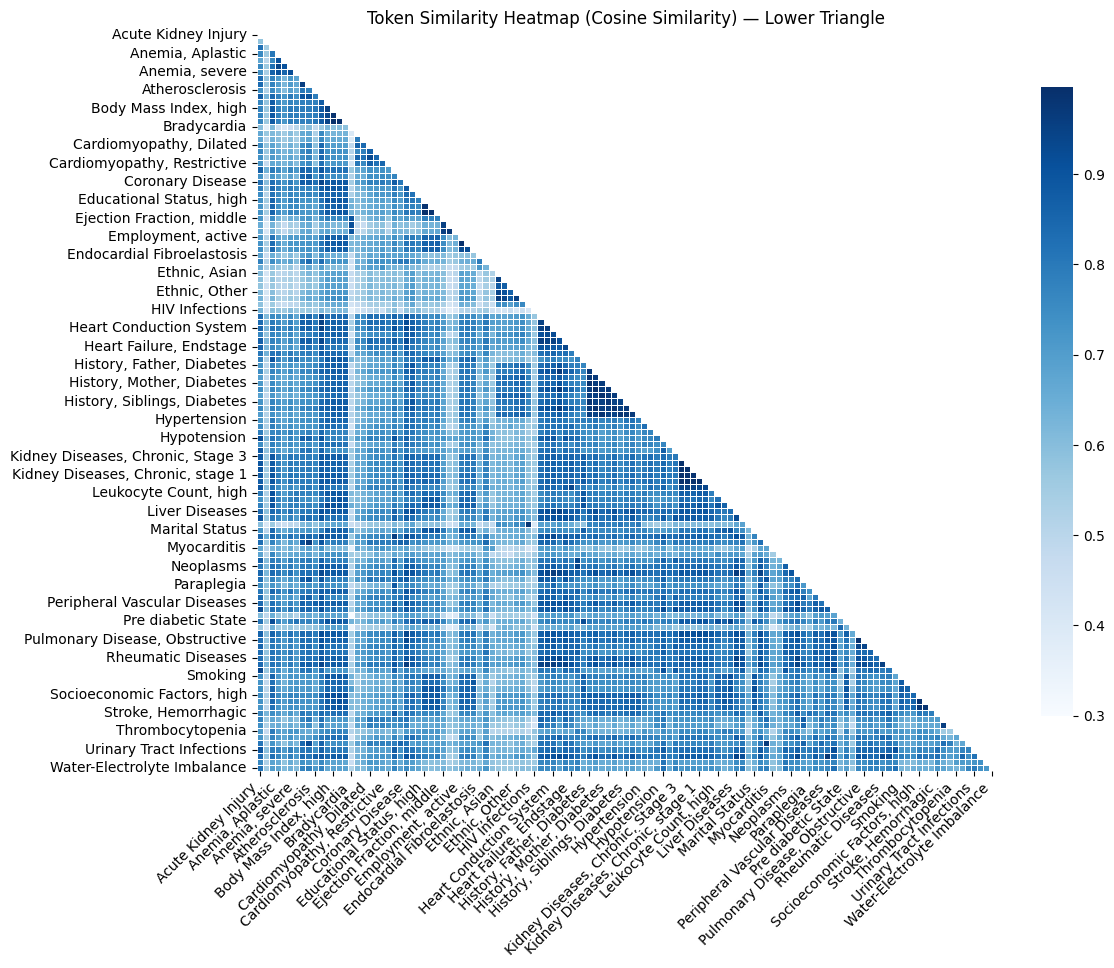

In [21]:
# Get sorted list of phrases for consistent order
phrases = sorted(phrase_embeddings_main_par.keys())

# Initialize an empty similarity matrix
similarity_matrix_main_par_full = np.zeros((len(phrases), len(phrases)))

# Fill the matrix
for i, phrase_i in enumerate(phrases):
    for j, phrase_j in enumerate(phrases):
        vec_i = phrase_embeddings_main_par[phrase_i]
        vec_j = phrase_embeddings_main_par[phrase_j]
        similarity = 1 - cosine(vec_i, vec_j)
        similarity_matrix_main_par_full[i, j] = similarity

# Convert to pandas DataFrame for readability
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

similarity_df_main_par_full = pd.DataFrame(similarity_matrix_main_par_full, index=phrases, columns=phrases)
similarity_df_main_par_full.to_csv("similarity_df_main_par_full.csv", index=False)

# Mask: hide upper triangle + diagonal -> show only lower triangle (excluding diagonal)
mask = np.triu(np.ones(similarity_df_main_par_full.shape, dtype=bool), k=0)

plt.figure(figsize=(12, 10))
sns.heatmap(
    similarity_df_main_par_full,
    mask=mask,
    cmap="Blues",          # light -> dark blue (one direction)
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Token Similarity Heatmap (Cosine Similarity) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_heatmap_main_par_full.svg", format="svg")
plt.show()

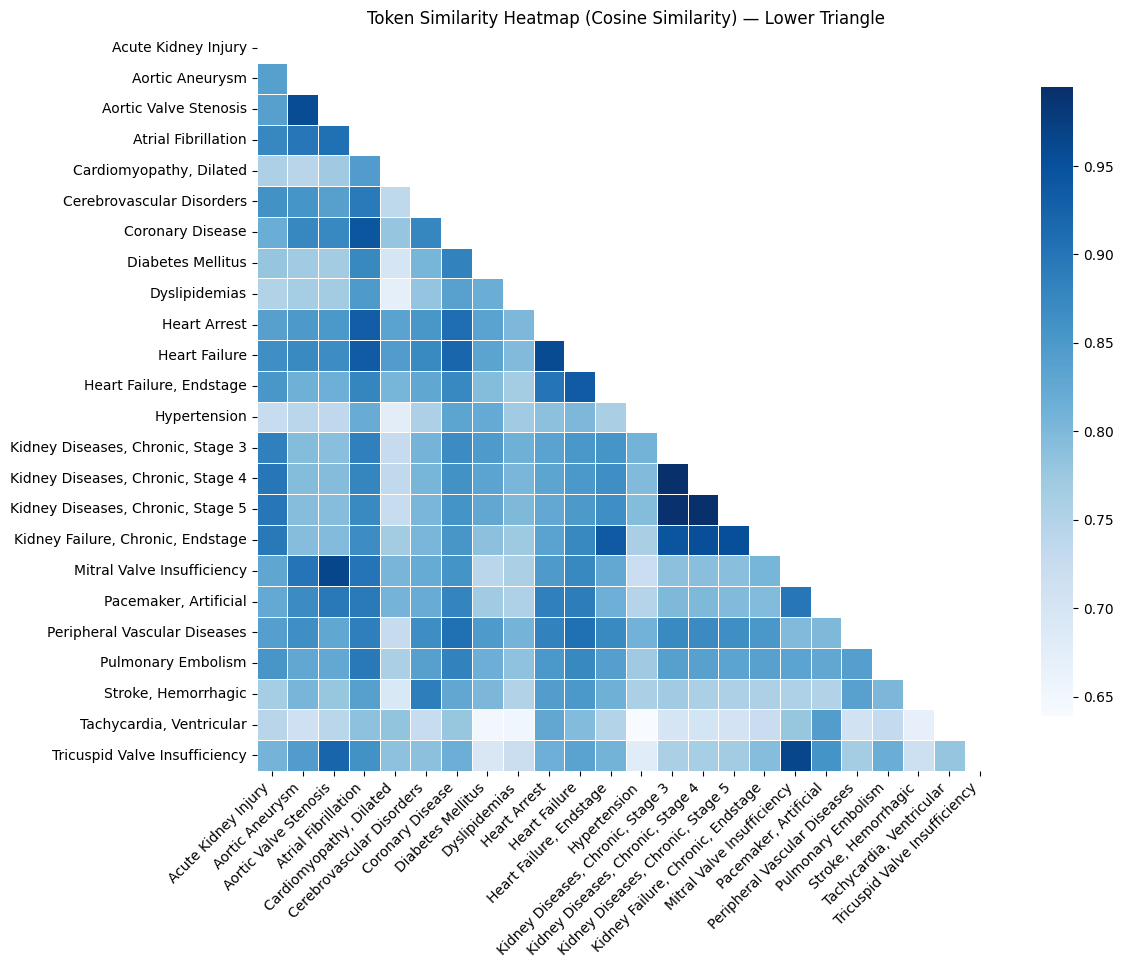

In [22]:
phrases_main = [p for p in phrases if p in df_main["disease_name"].unique()]

# Initialize an empty similarity matrix
similarity_matrix_main_par = np.zeros((len(phrases_main), len(phrases_main)))

# Fill the matrix
for i, phrase_i in enumerate(phrases_main):
    for j, phrase_j in enumerate(phrases_main):
        vec_i = phrase_embeddings_main_par[phrase_i]
        vec_j = phrase_embeddings_main_par[phrase_j]
        similarity = 1 - cosine(vec_i, vec_j)
        similarity_matrix_main_par[i, j] = similarity

# Convert to pandas DataFrame for readability
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

similarity_df_main_par = pd.DataFrame(similarity_matrix_main_par, index=phrases_main, columns=phrases_main)

# Mask: hide upper triangle + diagonal -> show only lower triangle (excluding diagonal)
mask = np.triu(np.ones(similarity_df_main_par.shape, dtype=bool), k=0)

plt.figure(figsize=(12, 10))
sns.heatmap(
    similarity_df_main_par,
    mask=mask,
    cmap="Blues",          # light -> dark blue (one direction)
    annot=False,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8} 
)

plt.title("Token Similarity Heatmap (Cosine Similarity) — Lower Triangle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_heatmap_main_par.svg", format="svg")
plt.show()

### 4. Network construction and visualization

In [23]:
import networkx as nx
def weighted_graph_construction(correlation_df, threshold):
    """
    Construct the weighted graph based on a correlation matrix.
 
    Parameters:
    - correlation_matrix: numpy array, input correlation matrix
    - threshold: float, correlation threshold for creating edges in the graph
 
    Returns:
    - G: graph, output weighted graph
    """
    # Create a graph from the correlation matrix with weights above the threshold
    correlation_matrix = np.absolute(np.array(correlation_df))
    G = nx.DiGraph()
    num_nodes = correlation_matrix.shape[0]
    prot_names = correlation_df.columns
    G.add_nodes_from(prot_names)
 
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            if np.abs(correlation_matrix[i, j]) > threshold:
                G.add_edge(prot_names[i], prot_names[j], weight=correlation_matrix[i, j])
    print(f'Proportion of #edges: {len(G.edges)/num_nodes**2}')
    G = G.to_undirected()
    return G
 
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib.cm as cm
import matplotlib.colors as mcolors

def plot_weighted_graph_colored(G, cmap_name="coolwarm"):
    """
    Plot a weighted graph with edge colors and transparency based on weight.
    Higher weights = more intense color + less transparency.

    Parameters:
    - G: NetworkX graph with 'weight' attributes on edges
    - cmap_name: Matplotlib colormap name
    """
    plt.figure(figsize=(16, 12))
    ax = plt.gca()
    pos = nx.circular_layout(G)

    # Extract edge weights
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    min_w, max_w = min(weights), max(weights)

    # Normalize weights
    norm = mcolors.Normalize(vmin=min_w, vmax=max_w)
    cmap = plt.colormaps[cmap_name]

    # Map weight to RGBA (color + alpha)
    edge_colors = []
    for w in weights:
        base_color = cmap(norm(w))
        alpha = 0.1 + 0.9 * norm(w)  # scale alpha from 0.1 (faint) to 1.0 (solid)
        edge_colors.append((base_color[0], base_color[1], base_color[2], alpha))

    # Draw graph
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color='lightgray')
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_color='black')
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=2)

    # Add colorbar
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
    cbar.set_label("Similarity", fontsize=12)

    plt.title("Graph Colored by Edge Similarity", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("graph_similarity_plot_main_par.svg", format="svg")
    
    plt.show()



Proportion of #edges: 0.4791666666666667


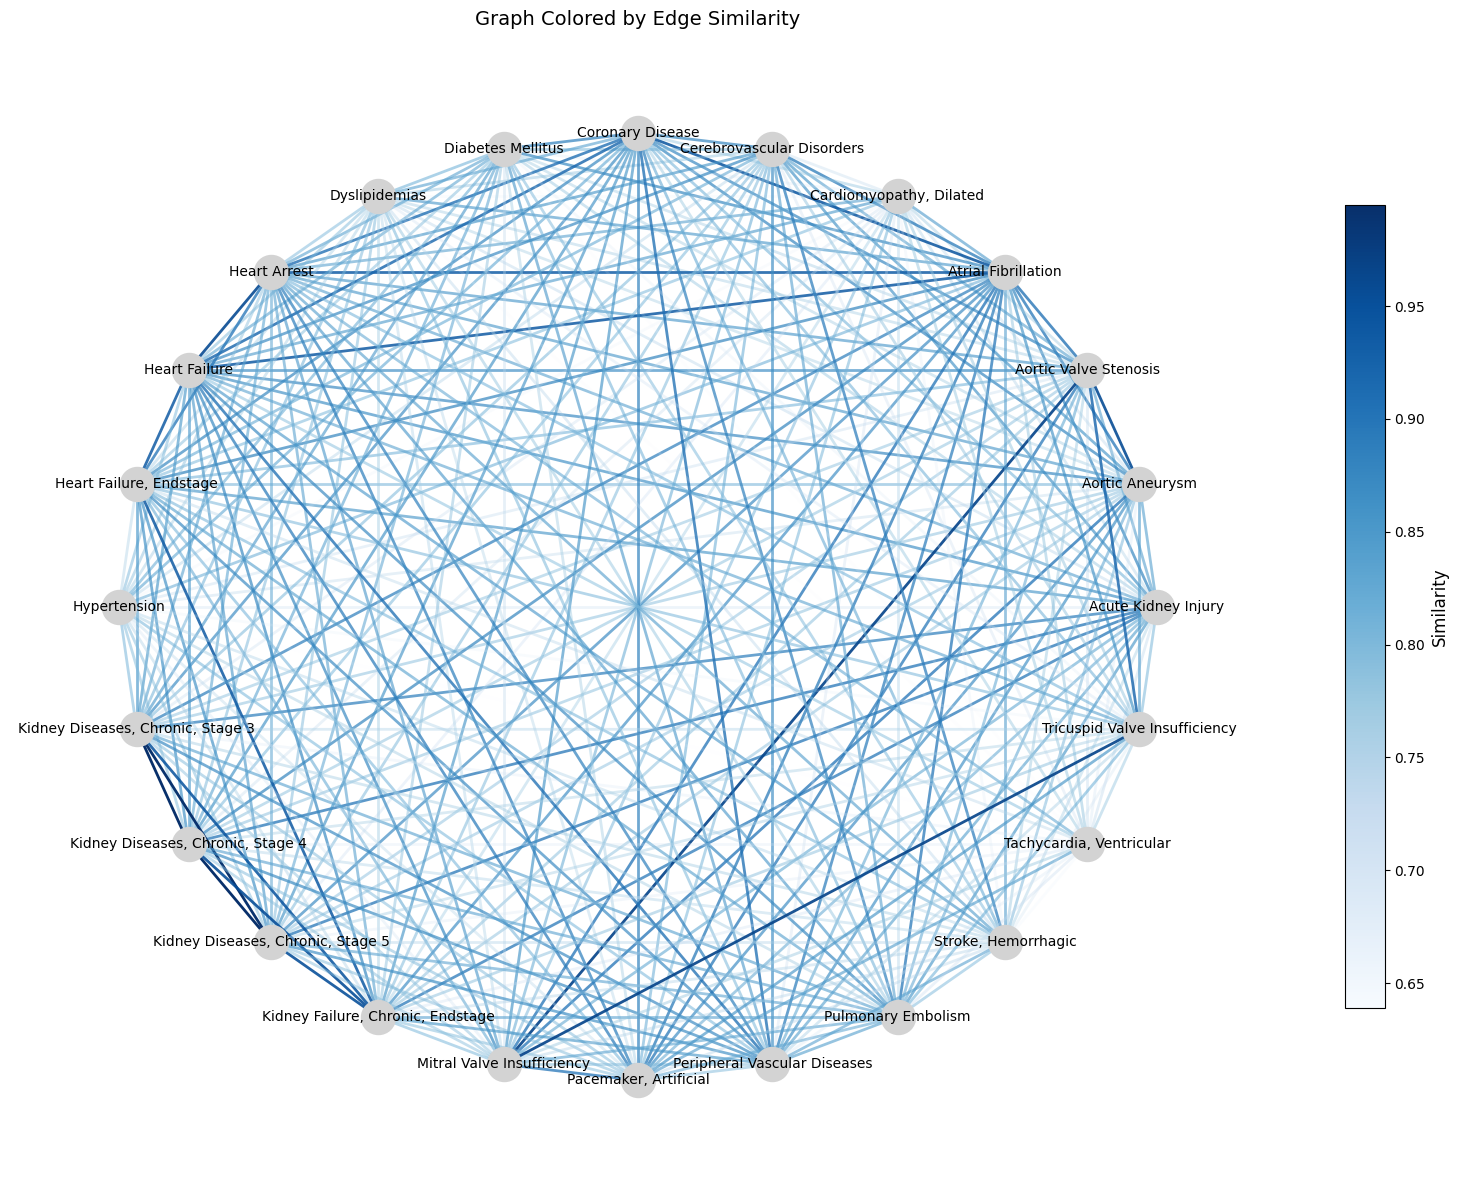

In [24]:
G = weighted_graph_construction(similarity_df_main_par, threshold=0.0)
plot_weighted_graph_colored(G, cmap_name="Blues")

# C. Network comparision

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import pearsonr, spearmanr, wilcoxon, ks_2samp
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

similarity_df_diff = pd.DataFrame(abs(similarity_matrix_main - similarity_matrix_main_par), 
                                 index=phrases_main, columns=phrases_main)

# Also create the signed difference for directional analysis
similarity_df_diff_signed = pd.DataFrame(similarity_matrix_main_par - similarity_matrix_main, 
                                        index=phrases_main, columns=phrases_main)

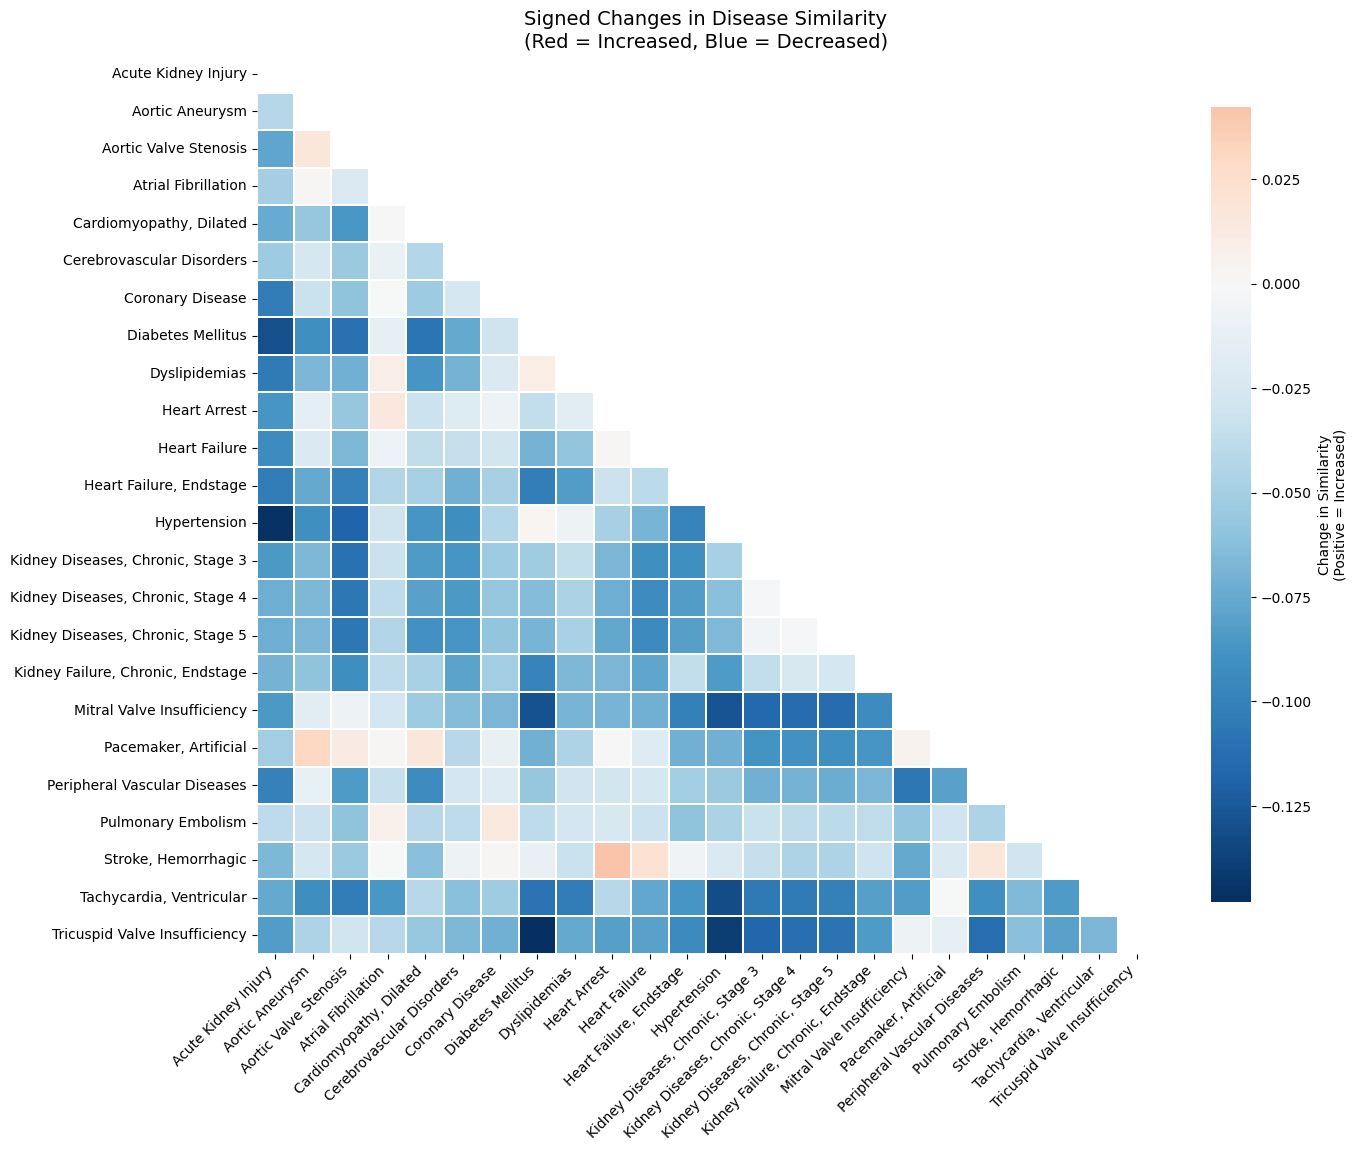

In [26]:
mask = np.triu(np.ones(similarity_df_diff_signed.shape, dtype=bool), k=0)

# Enhanced heatmap with signed differences
plt.figure(figsize=(14, 12))
sns.heatmap(similarity_df_diff_signed,
            mask=mask,
            cmap='RdBu_r', 
            center=0,
            annot=False, 
            fmt=".3f", 
            square=True,
            cbar_kws={"shrink": .8, "label": "Change in Similarity\n(Positive = Increased)"},
            linewidths=0.1)
plt.title("Signed Changes in Disease Similarity\n(Red = Increased, Blue = Decreased)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_changes_signed.svg", format="svg", dpi=300, bbox_inches='tight')
plt.show()

In [27]:
# =============================================================================
# 1. MATRIX-LEVEL COMPARISON STATISTICS
# =============================================================================
print("\n1. MATRIX-LEVEL STATISTICS")
print("-" * 30)

# Get upper triangular values (excluding diagonal)
mask = np.triu(np.ones_like(similarity_matrix_main, dtype=bool), k=1)
orig_values = similarity_matrix_main[mask]
modified_values = similarity_matrix_main_par[mask]
diff_values = similarity_df_diff_signed.values[mask]

# Basic difference statistics
mad = np.mean(np.abs(diff_values))
rmsd = np.sqrt(np.mean(diff_values**2))
max_change = np.max(np.abs(diff_values))
mean_change = np.mean(diff_values)
std_change = np.std(diff_values)

print(f"Mean Absolute Difference (MAD): {mad:.4f}")
print(f"Root Mean Square Difference (RMSD): {rmsd:.4f}")
print(f"Maximum Change: {max_change:.4f}")
print(f"Mean Change (directional): {mean_change:.4f}")
print(f"Standard Deviation of Changes: {std_change:.4f}")

# Percentage of relationships affected at different thresholds
thresh_001 = np.sum(np.abs(diff_values) > 0.01) / len(diff_values) * 100
thresh_005 = np.sum(np.abs(diff_values) > 0.05) / len(diff_values) * 100
thresh_010 = np.sum(np.abs(diff_values) > 0.10) / len(diff_values) * 100

print(f"\nPercentage of disease pairs affected:")
print(f"  >1% change: {thresh_001:.1f}%")
print(f"  >5% change: {thresh_005:.1f}%")
print(f"  >10% change: {thresh_010:.1f}%")


1. MATRIX-LEVEL STATISTICS
------------------------------
Mean Absolute Difference (MAD): 0.0584
Root Mean Square Difference (RMSD): 0.0673
Maximum Change: 0.1480
Mean Change (directional): -0.0568
Standard Deviation of Changes: 0.0361

Percentage of disease pairs affected:
  >1% change: 91.3%
  >5% change: 57.6%
  >10% change: 12.0%


In [30]:
np.sum(np.abs(diff_values) > 0.10)

33

In [31]:
# =============================================================================
# 2. CORRELATION ANALYSIS
# =============================================================================
print("\n2. CORRELATION ANALYSIS")
print("-" * 25)

# Correlation between original and modified matrices
pearson_r, pearson_p = pearsonr(orig_values, modified_values)
spearman_r, spearman_p = spearmanr(orig_values, modified_values)

print(f"Pearson correlation: {pearson_r:.4f} (p={pearson_p:.2e})")
print(f"Spearman rank correlation: {spearman_r:.4f} (p={spearman_p:.2e})")

# Interpretation
if pearson_r > 0.9:
    interpretation = "Excellent preservation - minimal confounding detected"
elif pearson_r > 0.7:
    interpretation = "Good preservation - moderate confounding effects"
elif pearson_r > 0.5:
    interpretation = "Fair preservation - substantial confounding detected"
else:
    interpretation = "Poor preservation - major structural changes"

print(f"Interpretation: {interpretation}")



2. CORRELATION ANALYSIS
-------------------------
Pearson correlation: 0.8306 (p=1.25e-71)
Spearman rank correlation: 0.8015 (p=3.80e-63)
Interpretation: Good preservation - moderate confounding effects


In [32]:
# =============================================================================
# 3. STATISTICAL SIGNIFICANCE TESTING
# =============================================================================
print("\n3. STATISTICAL SIGNIFICANCE")
print("-" * 28)

# Test if changes are systematically different from zero
statistic, p_value = wilcoxon(diff_values, alternative='two-sided')
print(f"Wilcoxon test for systematic change: p={p_value:.2e}")

if p_value < 0.001:
    print("Highly significant systematic changes detected")
elif p_value < 0.05:
    print("Significant systematic changes detected")
else:
    print("No systematic changes detected")

# Distribution comparison
ks_stat, ks_p = ks_2samp(orig_values, modified_values)
print(f"Kolmogorov-Smirnov test: KS={ks_stat:.4f}, p={ks_p:.2e}")


3. STATISTICAL SIGNIFICANCE
----------------------------
Wilcoxon test for systematic change: p=1.76e-44
Highly significant systematic changes detected
Kolmogorov-Smirnov test: KS=0.3949, p=1.33e-19


In [33]:
# =============================================================================
# 5. DISEASE PAIR CLASSIFICATION
# =============================================================================
print("\n5. MOST AFFECTED DISEASE PAIRS")
print("-" * 30)

# Find pairs with largest changes
diff_matrix = similarity_df_diff_signed.values
np.fill_diagonal(diff_matrix, 0)  # Remove diagonal

# Get indices of largest changes
flat_indices = np.argsort(np.abs(diff_matrix.flatten()))[::-1]
row_indices, col_indices = np.unravel_index(flat_indices, diff_matrix.shape)

print("Top 10 most affected disease pairs:")
print("Rank | Disease 1 → Disease 2 | Change | Direction")
print("-" * 55)

change_vec = []

count = 0
seen_pairs = set()
for i in range(len(flat_indices)):
    r, c = row_indices[i], col_indices[i]
    if r != c:  # Skip diagonal
        # Avoid duplicate pairs (r,c) and (c,r)
        pair = tuple(sorted([r, c]))
        if pair not in seen_pairs:
            change = diff_matrix[r, c]
            change_vec.append(change)
            direction = "Increased" if change > 0 else "Decreased"
            disease1 = phrases_main[r]
            disease2 = phrases_main[c]
            
            if count <= 14:
                print(f"{count+1:2d}   | {disease1} → {disease2} | {change:+.3f} | {direction}")
            
            seen_pairs.add(pair)
            count += 1                


5. MOST AFFECTED DISEASE PAIRS
------------------------------
Top 10 most affected disease pairs:
Rank | Disease 1 → Disease 2 | Change | Direction
-------------------------------------------------------
 1   | Tricuspid Valve Insufficiency → Diabetes Mellitus | -0.148 | Decreased
 2   | Acute Kidney Injury → Hypertension | -0.145 | Decreased
 3   | Tricuspid Valve Insufficiency → Hypertension | -0.140 | Decreased
 4   | Tachycardia, Ventricular → Hypertension | -0.132 | Decreased
 5   | Acute Kidney Injury → Diabetes Mellitus | -0.130 | Decreased
 6   | Mitral Valve Insufficiency → Diabetes Mellitus | -0.129 | Decreased
 7   | Mitral Valve Insufficiency → Hypertension | -0.128 | Decreased
 8   | Hypertension → Aortic Valve Stenosis | -0.118 | Decreased
 9   | Tricuspid Valve Insufficiency → Kidney Diseases, Chronic, Stage 3 | -0.117 | Decreased
10   | Mitral Valve Insufficiency → Kidney Diseases, Chronic, Stage 3 | -0.117 | Decreased
11   | Mitral Valve Insufficiency → Kidney Disease

95th percentile: 0.11078064140481236


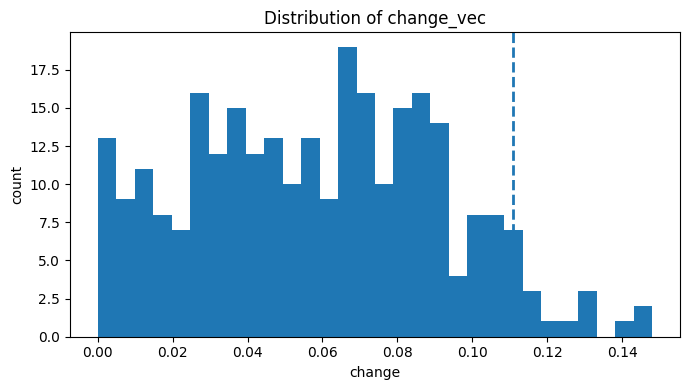

Number above the 95th percentile: 14


In [34]:
import numpy as np
import matplotlib.pyplot as plt

# make sure it's a numeric array and drop NaNs if any
x = np.asarray(np.abs(change_vec), dtype=float)
x = x[~np.isnan(x)]

if x.size == 0:
    raise ValueError("change_vec is empty (or all NaN).")

p95 = np.percentile(x, 95)
print("95th percentile:", p95)

plt.figure(figsize=(7, 4))
plt.hist(x, bins=30)
plt.axvline(p95, linestyle="--", linewidth=2)
plt.title("Distribution of change_vec")
plt.xlabel("change")
plt.ylabel("count")
plt.tight_layout()
plt.show()

n_above = np.sum(x > p95)
print("Number above the 95th percentile:", n_above)


In [35]:
risk_factors = set(df_main_par["disease_name"].dropna().unique()) - set(df_main["disease_name"].dropna().unique())
top_affected_pairs = [
    {"disease1": "Tricuspid Valve Insufficiency", "disease2": "Diabetes Mellitus", "change": -0.148, "direction": "Decreased"},
    {"disease1": "Acute Kidney Injury", "disease2": "Hypertension", "change": -0.145, "direction": "Decreased"},
    {"disease1": "Tricuspid Valve Insufficiency", "disease2": "Hypertension", "change": -0.140, "direction": "Decreased"},
    {"disease1": "Tachycardia, Ventricular", "disease2": "Hypertension", "change": -0.132, "direction": "Decreased"},
    {"disease1": "Acute Kidney Injury", "disease2": "Diabetes Mellitus", "change": -0.130, "direction": "Decreased"},
    {"disease1": "Mitral Valve Insufficiency", "disease2": "Diabetes Mellitus", "change": -0.129, "direction": "Decreased"},
    {"disease1": "Mitral Valve Insufficiency", "disease2": "Hypertension", "change": -0.128, "direction": "Decreased"},
    {"disease1": "Hypertension", "disease2": "Aortic Valve Stenosis", "change": -0.118, "direction": "Decreased"},
    {"disease1": "Tricuspid Valve Insufficiency", "disease2": "Kidney Diseases, Chronic, Stage 3", "change": -0.117, "direction": "Decreased"},
    {"disease1": "Mitral Valve Insufficiency", "disease2": "Kidney Diseases, Chronic, Stage 3", "change": -0.117, "direction": "Decreased"},
    {"disease1": "Mitral Valve Insufficiency", "disease2": "Kidney Diseases, Chronic, Stage 4", "change": -0.114, "direction": "Decreased"},
    {"disease1": "Mitral Valve Insufficiency", "disease2": "Kidney Diseases, Chronic, Stage 5", "change": -0.113, "direction": "Decreased"},
    {"disease1": "Kidney Diseases, Chronic, Stage 4", "disease2": "Tricuspid Valve Insufficiency", "change": -0.112, "direction": "Decreased"},
    {"disease1": "Peripheral Vascular Diseases", "disease2": "Tricuspid Valve Insufficiency", "change": -0.112, "direction": "Decreased"},
]
# Extract unique diseases from these pairs
unique_diseases = set()
for pair in top_affected_pairs:
    unique_diseases.add(pair["disease1"])
    unique_diseases.add(pair["disease2"])

unique_diseases = list(unique_diseases)

In [36]:
def find_correlated_risk_factors(disease_name, risk_factors, similarity_matrix_par, 
                                disease_names_par, threshold=0.5, top_n=10):
    """
    Find risk factors highly correlated with a specific disease
    
    Parameters:
    - disease_name: name of the disease to analyze
    - risk_factors: list of risk factor names
    - similarity_matrix_par: the second similarity matrix (with risk factors)
    - disease_names_par: list of all names in the second matrix (diseases + risk factors)
    - threshold: minimum correlation threshold
    - top_n: number of top correlations to return
    """
    
    # Find the index of the disease in the second matrix
    if disease_name not in disease_names_par:
        print(f"Warning: {disease_name} not found in second matrix")
        return []
    
    disease_idx = disease_names_par.index(disease_name)
    
    # Find correlations with all risk factors
    correlations = []
    
    for rf in risk_factors:
        if rf in disease_names_par:
            rf_idx = disease_names_par.index(rf)
            correlation = similarity_matrix_par[disease_idx, rf_idx]
            
            if correlation >= threshold:
                correlations.append({
                    'risk_factor': rf,
                    'correlation': correlation
                })
    
    # Sort by correlation strength
    correlations.sort(key=lambda x: x['correlation'], reverse=True)
    
    return correlations[:top_n]


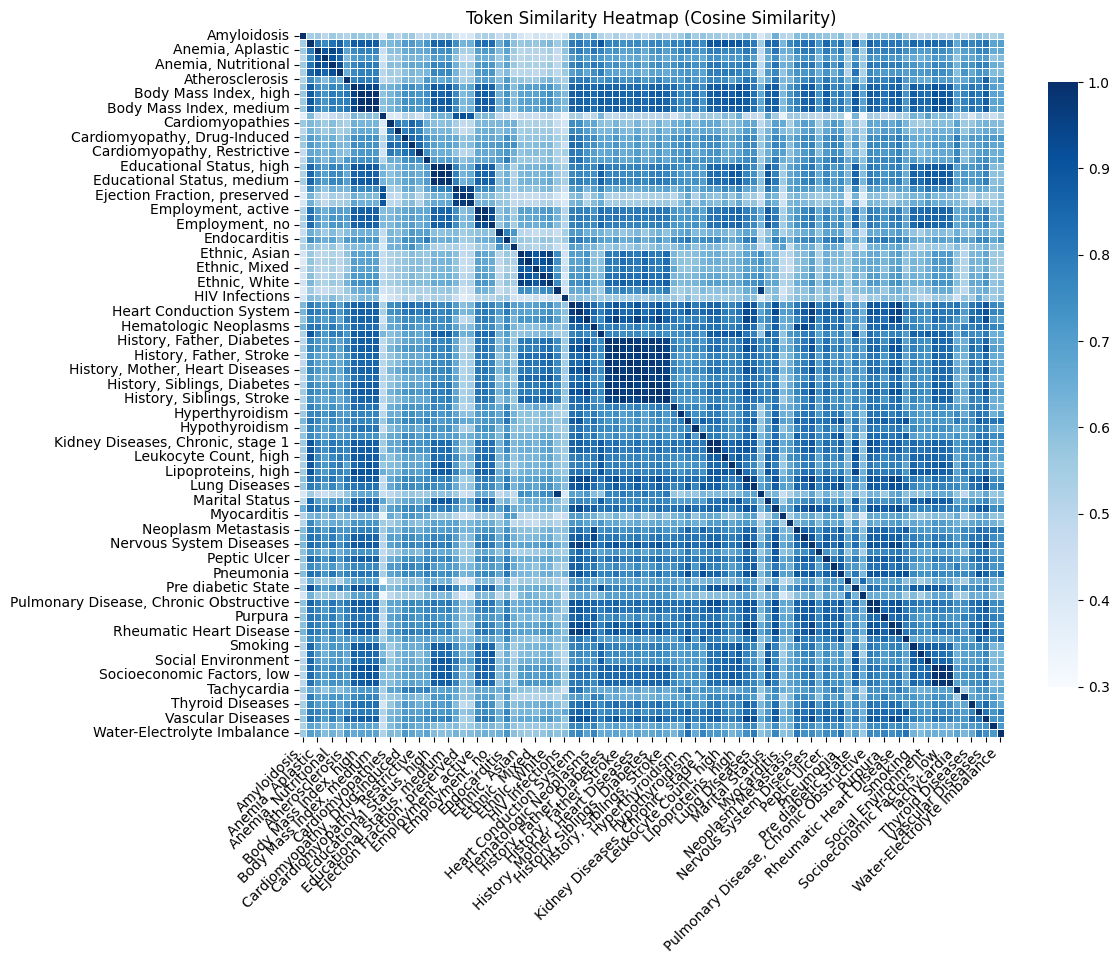

In [37]:
rf = sorted(set(risk_factors) & set(similarity_df_main_par_full.index) & set(similarity_df_main_par_full.columns))
similarity_df_matrix_par = similarity_df_main_par_full.loc[rf, rf]

plt.figure(figsize=(12, 10))
sns.heatmap(similarity_df_matrix_par, cmap='Blues', annot=False, fmt=".2f", square=True,
            cbar_kws={"shrink": .8}, linewidths=.5)

plt.title("Token Similarity Heatmap (Cosine Similarity)")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("disease_similarity_heatmap_par.svg", format="svg")

plt.show()

In [38]:
correlation_treshold = round(np.median(similarity_df_matrix_par), 2)
correlation_treshold 

0.72

In [90]:
round(np.quantile(similarity_df_matrix_par,  0.05),2)

0.52

In [94]:
round(np.median(similarity_df_main_par_full), 2)

0.74

In [98]:
round(np.quantile(similarity_df_main_par_full,  0.75), 2)

0.81

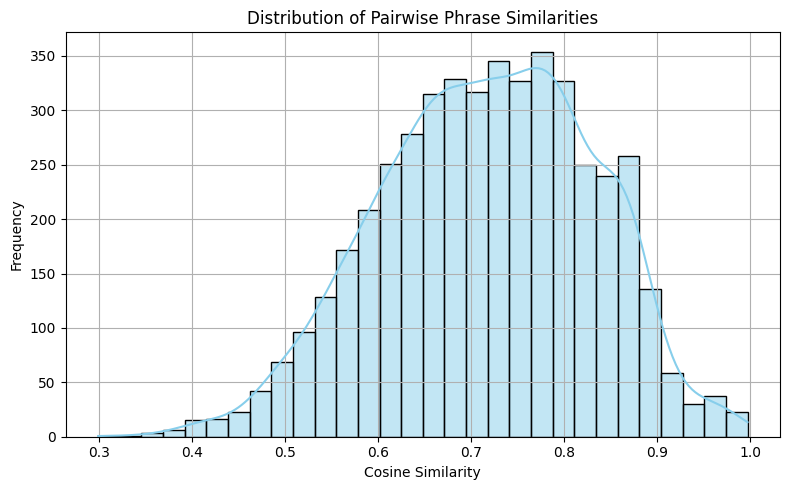

In [39]:
upper_tri_values = similarity_df_matrix_par.where(np.triu(np.ones(similarity_df_matrix_par.shape), k=1).astype(bool)).stack()

# Plot distribution
plt.figure(figsize=(8, 5))
sns.histplot(upper_tri_values, bins=30, kde=True, color='skyblue')
plt.title("Distribution of Pairwise Phrase Similarities")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
phrases_main_par = df_main_par['disease_name'].unique()

def analyze_disease_risk_correlations(diseases, risk_factors, phrases_main_par, similarity_matrix_main_par, threshold=0.5):
    """
    ACTUAL ANALYSIS - Find risk factors highly correlated with each disease
    """
    
    print(f"\nAnalyzing correlations for {len(diseases)} diseases...")
    print(f"Using correlation threshold: {threshold}")
    print(f"Available risk factors: {len(risk_factors)}")
    
    # Convert phrases_main_par to a proper list regardless of input type
    if hasattr(phrases_main_par, '__call__'):
        #print("phrases_main_par appears to be a function/method - trying to call it...")
        try:
            phrases_list = list(phrases_main_par())
        except:
            print("ERROR: Could not call phrases_main_par(). Please provide it as a list.")
            return {}
    elif isinstance(phrases_main_par, np.ndarray):
        #print("phrases_main_par is a numpy array - converting to list...")
        phrases_list = phrases_main_par.tolist()
    elif hasattr(phrases_main_par, 'tolist'):
        print("phrases_main_par has tolist method - converting...")
        phrases_list = phrases_main_par.tolist()
    elif hasattr(phrases_main_par, 'values'):
        print("phrases_main_par appears to be a pandas object - extracting values...")
        phrases_list = list(phrases_main_par.values)
    else:
        #print("phrases_main_par appears to be a list - using directly...")
        phrases_list = list(phrases_main_par)
    
    #print(f"Total entities in second matrix: {len(phrases_list)}")
    #print(f"First few entities: {phrases_list[:3] if len(phrases_list) > 0 else 'None'}")
    #print(f"Data type after conversion: {type(phrases_list)}")
    
    disease_risk_correlations = {}
    
    for disease in diseases:
        print(f"\n--- Analyzing {disease} ---")
        
        # Use list methods since we converted to list
        if disease in phrases_list:
            disease_idx = phrases_list.index(disease)
            print(f"Found {disease} at index {disease_idx}")
            
            # Find correlations with risk factors
            correlations = []
            rf_found = 0
            
            for rf in risk_factors:
                if rf in phrases_list:
                    rf_idx = phrases_list.index(rf)
                    correlation = similarity_matrix_main_par[disease_idx, rf_idx]
                    rf_found += 1
                    
                    if correlation >= threshold:
                        correlations.append({
                            'risk_factor': rf,
                            'correlation': correlation
                        })
            
            #print(f"Risk factors found in matrix: {rf_found}/{len(risk_factors)}")
            
            # Sort by correlation strength
            correlations.sort(key=lambda x: x['correlation'], reverse=True)
            disease_risk_correlations[disease] = correlations#[:10]  # Top 10
            
            print(f"High correlations found (≥{threshold}): {len(correlations)}")
            if correlations:
                print("Top risk factor correlations:")
                for corr in correlations[:5]:  # Show top 5
                    print(f"  • {corr['risk_factor']}: {corr['correlation']:.3f}")
            else:
                print(f"  • No risk factors above threshold {threshold}")
                
                # Show some correlations below threshold for debugging
                all_corrs = []
                for rf in risk_factors:  # Check first 10 RF
                    if rf in phrases_list:
                        rf_idx = phrases_list.index(rf)
                        correlation = similarity_matrix_main_par[disease_idx, rf_idx]
                        all_corrs.append((rf, correlation))
                
                all_corrs.sort(key=lambda x: x[1], reverse=True)
                print(f"  Top correlations (any threshold):")
                for rf, corr in all_corrs[:3]:
                    print(f"    • {rf}: {corr:.3f}")
                    
        else:
            print(f"  • WARNING: {disease} not found in phrases_main_par")
            print(f"  • Similar names in list: {[p for p in phrases_list if disease.lower() in p.lower() or p.lower() in disease.lower()][:3]}")
            disease_risk_correlations[disease] = []
    
    return disease_risk_correlations

# Run the ACTUAL analysis with your data
disease_correlations = analyze_disease_risk_correlations(
    unique_diseases, risk_factors, phrases_main_par, similarity_matrix_main_par_full, threshold=correlation_treshold
)



Analyzing correlations for 11 diseases...
Using correlation threshold: 0.72
Available risk factors: 97

--- Analyzing Tricuspid Valve Insufficiency ---
Found Tricuspid Valve Insufficiency at index 73
High correlations found (≥0.72): 75
Top risk factor correlations:
  • History, Siblings, Diabetes: 0.997
  • Heart Diseases: 0.994
  • Anemia, severe: 0.939
  • Heart Conduction System: 0.918
  • Liver Diseases: 0.894

--- Analyzing Aortic Valve Stenosis ---
Found Aortic Valve Stenosis at index 87
High correlations found (≥0.72): 76
Top risk factor correlations:
  • Liver Diseases: 0.894
  • Employment, active: 0.890
  • Ethnic, Asian: 0.883
  • Heart Conduction System: 0.880
  • Cardiomyopathy, Hypertrophic: 0.879

--- Analyzing Diabetes Mellitus ---
Found Diabetes Mellitus at index 19
High correlations found (≥0.72): 43
Top risk factor correlations:
  • Kidney Diseases, Chronic, stage 1: 0.868
  • Hypothyroidism: 0.849
  • Employment, active: 0.840
  • Pneumonia: 0.827
  • Lung Diseases

In [41]:
def analyze_pair_shared_risk_factors(pair, disease_correlations):
    """
    Analyze shared risk factors for a specific disease pair
    """
    disease1 = pair['disease1']
    disease2 = pair['disease2']
    change = pair['change']
    direction = pair['direction']
    
    print(f"\n--- {disease1} ↔ {disease2} ---")
    print(f"Change: {change:+.3f} ({direction})")
    
    # Get risk factors for each disease
    rf1 = disease_correlations.get(disease1, [])
    rf2 = disease_correlations.get(disease2, [])
    
    # Find shared risk factors
    rf1_names = {corr['risk_factor'] for corr in rf1}
    rf2_names = {corr['risk_factor'] for corr in rf2}
    shared_rf = rf1_names.intersection(rf2_names)
    
    print(f"Disease 1 high-correlated RF: {len(rf1)}")
    print(f"Disease 2 high-correlated RF: {len(rf2)}")
    print(f"Shared high-correlated RF: {len(shared_rf)}")
    
    if shared_rf:
        print("Shared risk factors (Disease1 | Disease2):")
        for rf in list(shared_rf)[:10]:  # Show top 10 shared
            # Get correlations for this shared risk factor
            corr1 = next((c['correlation'] for c in rf1 if c['risk_factor'] == rf), 0)
            corr2 = next((c['correlation'] for c in rf2 if c['risk_factor'] == rf), 0)
            print(f"  • {rf}: {corr1:.3f} | {corr2:.3f}")
    else:
        print("  • No shared high-correlation risk factors")
    
    # Clinical interpretation
    print("Clinical interpretation:")
    if change < 0 and len(shared_rf) > 3:
        print("  → CONFOUNDING DETECTED: High shared RF explains original similarity")
        print("  → Risk adjustment correctly REDUCED artificial correlation")
    elif change > 0 and len(shared_rf) < 2:
        print("  → TRUE RELATIONSHIP: Few shared RF, similarity INCREASED")
        print("  → Risk adjustment revealed genuine pathophysiological link")
    elif change < 0 and len(shared_rf) <= 1:
        print("  → UNEXPECTED: Large decrease but few shared RF")
        print("  → May indicate other confounding mechanisms")
    else:
        print("  → MIXED PATTERN: Requires further investigation")
    
    return {
        'pair': f"{disease1} ↔ {disease2}",
        'change': change,
        'direction': direction,
        'shared_rf': list(shared_rf),
        'n_shared': len(shared_rf),
        'disease1_rf_count': len(rf1),
        'disease2_rf_count': len(rf2)
    }

# Analyze each of the 10 pairs
print("ANALYZING ALL 10 PAIRS:")
print("="*60)

pair_analyses = []
for i, pair in enumerate(top_affected_pairs, 1):
    print(f"\n🔍 PAIR {i}/10:")
    analysis = analyze_pair_shared_risk_factors(pair, disease_correlations)
    pair_analyses.append(analysis)


ANALYZING ALL 10 PAIRS:

🔍 PAIR 1/10:

--- Tricuspid Valve Insufficiency ↔ Diabetes Mellitus ---
Change: -0.148 (Decreased)
Disease 1 high-correlated RF: 75
Disease 2 high-correlated RF: 43
Shared high-correlated RF: 40
Shared risk factors (Disease1 | Disease2):
  • Kidney Diseases, Chronic, stage 1: 0.728 | 0.868
  • Rheumatic Diseases: 0.785 | 0.802
  • Liver Diseases: 0.894 | 0.762
  • Ethnic, Asian: 0.861 | 0.762
  • Marital Status: 0.876 | 0.737
  • Hyperthyroidism: 0.846 | 0.751
  • History, Siblings, Diabetes: 0.997 | 0.756
  • Smoking: 0.830 | 0.764
  • Body Mass Index, medium: 0.767 | 0.741
  • Educational Status, high: 0.880 | 0.740
Clinical interpretation:
  → CONFOUNDING DETECTED: High shared RF explains original similarity
  → Risk adjustment correctly REDUCED artificial correlation

🔍 PAIR 2/10:

--- Acute Kidney Injury ↔ Hypertension ---
Change: -0.145 (Decreased)
Disease 1 high-correlated RF: 76
Disease 2 high-correlated RF: 33
Shared high-correlated RF: 27
Shared risk 

In [43]:
import pandas as pd

# Assume top_affected_pairs and disease_correlations are already defined.

def analyze_pair_shared_risk_factors_min(pair, disease_correlations):
    disease1 = pair['disease1']
    disease2 = pair['disease2']
    
    rf1 = disease_correlations.get(disease1, [])
    rf2 = disease_correlations.get(disease2, [])
    
    rf1_names = {corr['risk_factor'] for corr in rf1}
    rf2_names = {corr['risk_factor'] for corr in rf2}
    
    shared_rf = rf1_names.intersection(rf2_names)

    return {
        'pair': f"{disease1} ↔ {disease2}",
        'n_rf_disease1': len(rf1),
        'n_rf_disease2': len(rf2),
        'n_shared': len(shared_rf),
        'normalized_shared': len(shared_rf) / min(len(rf1), len(rf2)) if min(len(rf1), len(rf2)) > 0 else 0,
        'change': similarity_df_diff_signed.loc[disease1,disease2 ]
    }

def analyze_pair_shared_risk_factors(pair, disease_correlations):
    disease1 = pair["disease1"]
    disease2 = pair["disease2"]

    rf1 = disease_correlations.get(disease1, [])
    rf2 = disease_correlations.get(disease2, [])

    rf1_names = {corr["risk_factor"] for corr in rf1}
    rf2_names = {corr["risk_factor"] for corr in rf2}

    shared_rf = rf1_names & rf2_names
    union_rf = rf1_names | rf2_names

    jaccard = (len(shared_rf) / len(union_rf)) if len(union_rf) > 0 else 0

    return {
        "pair": f"{disease1} ↔ {disease2}",
        "n_rf_disease1": len(rf1),
        "n_rf_disease2": len(rf2),
        "n_shared": len(shared_rf),
        "normalized_shared": jaccard,  # Jaccard similarity
        "change": similarity_df_diff_signed.loc[disease1, disease2],
    }


# Run the analysis
pair_analyses = [analyze_pair_shared_risk_factors_min(pair, disease_correlations) for pair in top_affected_pairs]

# Convert to DataFrame
df_results = pd.DataFrame(pair_analyses)

# Sort or display as needed
df_results = df_results[['pair', 'n_rf_disease1', 'n_rf_disease2', 'n_shared', 'normalized_shared']]
df_results.sort_values(by='normalized_shared', ascending=False, inplace=True)
indices = df_results.index.tolist()
indices_inverted = indices[::-1]

# Riordina il DataFrame secondo questa lista invertita
df_results_sorted = df_results.loc[indices_inverted].reset_index(drop=True)

df_results_sorted

,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared
0,"Tachycardia, Ventricular ↔ Hypertension",48,33,16,0.484848
1,Mitral Valve Insufficiency ↔ Hypertension,36,33,21,0.636364
2,Acute Kidney Injury ↔ Hypertension,76,33,27,0.818182
3,Mitral Valve Insufficiency ↔ Diabetes Mellitus,36,43,30,0.833333
4,Acute Kidney Injury ↔ Diabetes Mellitus,76,43,37,0.860465
5,Hypertension ↔ Aortic Valve Stenosis,33,76,29,0.878788
6,Tricuspid Valve Insufficiency ↔ Hypertension,75,33,30,0.909091
7,Tricuspid Valve Insufficiency ↔ Diabetes Mellitus,75,43,40,0.930233
8,Peripheral Vascular Diseases ↔ Tricuspid Valve...,58,75,56,0.965517
9,Tricuspid Valve Insufficiency ↔ Kidney Disease...,75,64,63,0.984375


In [46]:
df_results.loc[range(0,14)]

,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared
0,Tricuspid Valve Insufficiency ↔ Diabetes Mellitus,75,43,40,0.930233
1,Acute Kidney Injury ↔ Hypertension,76,33,27,0.818182
2,Tricuspid Valve Insufficiency ↔ Hypertension,75,33,30,0.909091
3,"Tachycardia, Ventricular ↔ Hypertension",48,33,16,0.484848
4,Acute Kidney Injury ↔ Diabetes Mellitus,76,43,37,0.860465
5,Mitral Valve Insufficiency ↔ Diabetes Mellitus,36,43,30,0.833333
6,Mitral Valve Insufficiency ↔ Hypertension,36,33,21,0.636364
7,Hypertension ↔ Aortic Valve Stenosis,33,76,29,0.878788
8,Tricuspid Valve Insufficiency ↔ Kidney Disease...,75,64,63,0.984375
9,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",36,64,36,1.000000


In [50]:
np.mean(df_results['normalized_shared'])

0.8777044745050459

In [52]:
np.std(df_results['normalized_shared'])

0.14588808814002055

#### Sensitivity analysis

In [55]:
def analyze_disease_risk_correlations_for_loop(diseases, risk_factors, phrases_main_par, similarity_matrix_main_par, threshold=0.5):
    """
    ACTUAL ANALYSIS - Find risk factors highly correlated with each disease
    """
    
    # Convert phrases_main_par to a proper list regardless of input type
    if hasattr(phrases_main_par, '__call__'):
        #print("phrases_main_par appears to be a function/method - trying to call it...")
        try:
            phrases_list = list(phrases_main_par())
        except:
            print("ERROR: Could not call phrases_main_par(). Please provide it as a list.")
            return {}
    elif isinstance(phrases_main_par, np.ndarray):
        #print("phrases_main_par is a numpy array - converting to list...")
        phrases_list = phrases_main_par.tolist()
    elif hasattr(phrases_main_par, 'tolist'):
        phrases_list = phrases_main_par.tolist()
    elif hasattr(phrases_main_par, 'values'):
        phrases_list = list(phrases_main_par.values)
    else:
        #print("phrases_main_par appears to be a list - using directly...")
        phrases_list = list(phrases_main_par)
        
    disease_risk_correlations = {}
    
    for disease in diseases:
        
        # Use list methods since we converted to list
        if disease in phrases_list:
            disease_idx = phrases_list.index(disease)
            
            # Find correlations with risk factors
            correlations = []
            rf_found = 0
            
            for rf in risk_factors:
                if rf in phrases_list:
                    rf_idx = phrases_list.index(rf)
                    correlation = similarity_matrix_main_par[disease_idx, rf_idx]
                    rf_found += 1
                    
                    if correlation >= threshold:
                        correlations.append({
                            'risk_factor': rf,
                            'correlation': correlation
                        })
            
            # Sort by correlation strength
            correlations.sort(key=lambda x: x['correlation'], reverse=True)
            disease_risk_correlations[disease] = correlations#[:10]  # Top 10
                                
        else:
            disease_risk_correlations[disease] = []
    
    return disease_risk_correlations

In [68]:
import numpy as np

# Find pairs with largest changes
diff_matrix = similarity_df_diff_signed.values
np.fill_diagonal(diff_matrix, 0)  # Remove diagonal

# Get indices of largest absolute changes
flat_indices = np.argsort(np.abs(diff_matrix.flatten()))[::-1]

top_affected_pairs = []          # this is the output you want
max_pairs = 15                   # how many top pairs to keep
seen_pairs = set()

for idx in flat_indices:
    r, c = np.unravel_index(idx, diff_matrix.shape)

    if r == c:     # skip diagonal
        continue

    # avoid duplicate pairs (r,c) vs (c,r)
    pair_key = tuple(sorted((r, c)))
    if pair_key in seen_pairs:
        continue

    change = diff_matrix[r, c]
    direction = "Increased" if change > 0 else "Decreased"
    disease1 = phrases_main[r]
    disease2 = phrases_main[c]

    top_affected_pairs.append({
        "disease1": disease1,
        "disease2": disease2,
        "change": round(float(change), 3),  # round to 3 decimals like your example
        "direction": direction
    })

    seen_pairs.add(pair_key)

In [93]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

correlation_threshold_vec = [0.5, 0.6, 0.70, 0.72, 0.8, 0.9]  # or more thresholds if you like, e.g. [0.70, 0.73, 0.75]

all_results = None  # final wide table: pair + normalized_shared per threshold

for t in correlation_threshold_vec:
    temp_disease_correlations = analyze_disease_risk_correlations_for_loop(
        unique_diseases,
        risk_factors,
        phrases_main_par,
        similarity_matrix_main_par_full,
        threshold=t
    )

    # analysis for all pairs you care about
    pair_analyses_temp = [
        analyze_pair_shared_risk_factors_min(pair, temp_disease_correlations)
        for pair in top_affected_pairs  # or whatever list of pairs you use
    ]

    df_results_temp = pd.DataFrame(pair_analyses_temp)

    # keep only pair + normalized_shared
    df_results_temp = df_results_temp[['pair', 'normalized_shared']]

    # rename normalized_shared column to the threshold value
    col_name = f"{t}"
    df_results_temp = df_results_temp.rename(columns={'normalized_shared': col_name})

    # merge into wide table
    if all_results is None:
        all_results = df_results_temp
    else:
        all_results = all_results.merge(df_results_temp, on='pair', how='outer')

    # (optional) print summary stats per threshold
    mean_val = df_results_temp[col_name].mean()
    sd_val   = df_results_temp[col_name].std()
    print(f"Threshold {t}")
    print(f"  mean normalized_shared = {mean_val:.4f}")
    print(f"  sd   normalized_shared = {sd_val:.4f}\n")

# ---------- Wilcoxon (Mann–Whitney) test: first 14 rows vs the others ----------

top_n = 14

for t in correlation_threshold_vec:
    col_name = f"{t}"

    # group 1: first 14 rows
    group_top = all_results[col_name].iloc[:top_n].dropna()

    # group 2: all remaining rows
    group_rest = all_results[col_name].iloc[top_n:].dropna()

    # safety check: need data in both groups
    if len(group_top) == 0 or len(group_rest) == 0:
        print(f"Threshold {t}: not enough data for Wilcoxon test.")
        continue

    stat, p_value = mannwhitneyu(group_top, group_rest, alternative='greater')

    print(f"Threshold {t}: Wilcoxon rank-sum p-value (first {top_n} vs others) = {p_value:.4g}")

# ---------- Keep only the first 14 rows in all_results ----------

all_results_top = all_results.iloc[:top_n].copy()
print("\nall_results (first 14 rows):")
print(all_results_top.head(14))


Threshold 0.5
  mean normalized_shared = 0.1991
  sd   normalized_shared = 0.3999

Threshold 0.6
  mean normalized_shared = 0.1964
  sd   normalized_shared = 0.3944

Threshold 0.7
  mean normalized_shared = 0.1877
  sd   normalized_shared = 0.3781

Threshold 0.72
  mean normalized_shared = 0.1795
  sd   normalized_shared = 0.3648

Threshold 0.8
  mean normalized_shared = 0.1165
  sd   normalized_shared = 0.2780

Threshold 0.9
  mean normalized_shared = 0.0030
  sd   normalized_shared = 0.0382

Threshold 0.5: Wilcoxon rank-sum p-value (first 14 vs others) = 8.512e-15
Threshold 0.6: Wilcoxon rank-sum p-value (first 14 vs others) = 5.236e-15
Threshold 0.7: Wilcoxon rank-sum p-value (first 14 vs others) = 6.429e-14
Threshold 0.72: Wilcoxon rank-sum p-value (first 14 vs others) = 2.572e-14
Threshold 0.8: Wilcoxon rank-sum p-value (first 14 vs others) = 9.673e-11
Threshold 0.9: Wilcoxon rank-sum p-value (first 14 vs others) = 0.002005

all_results (first 14 rows):
                           

In [82]:
t=0.9
col_name = f"{t}"
top_n=14

# group 1: first 14 rows
group_top = all_results[col_name].iloc[:top_n].dropna()

# group 2: all remaining rows
group_rest = all_results[col_name].iloc[top_n:].dropna()

stat, p_value = mannwhitneyu(group_top, group_rest, alternative='greater')
print(p_value)

0.00200511271242864


In [75]:
all_results.to_csv("Sensitibity_analysis.csv")

In [47]:
#TO BE COMPLETED
print(f"\n5. SUMMARY STATISTICS AND VALIDATION")
print("-" * 40)

# Separate decreased vs increased pairs
decreased_pairs = [p for p in pair_analyses if p['change'] < 0]
increased_pairs = [p for p in pair_analyses if p['change'] > 0]

print(f"OVERALL SUMMARY:")
print(f"  • Total pairs analyzed: {len(pair_analyses)}")
print(f"  • Decreased similarity pairs: {len(decreased_pairs)}")
print(f"  • Increased similarity pairs: {len(increased_pairs)}")

if decreased_pairs:
    avg_shared_decreased = np.mean([p['n_shared'] for p in decreased_pairs])
    max_shared_decreased = max([p['n_shared'] for p in decreased_pairs])
    print(f"  • Avg shared RF in decreased pairs: {avg_shared_decreased:.1f}")
    print(f"  • Max shared RF in decreased pairs: {max_shared_decreased}")

if increased_pairs:
    avg_shared_increased = np.mean([p['n_shared'] for p in increased_pairs])
    max_shared_increased = max([p['n_shared'] for p in increased_pairs])
    print(f"  • Avg shared RF in increased pairs: {avg_shared_increased:.1f}")
    print(f"  • Max shared RF in increased pairs: {max_shared_increased}")

# =============================================================================
# 7. CONFOUNDING VALIDATION RESULTS
# =============================================================================

print(f"\n6. CONFOUNDING VALIDATION RESULTS")
print("-" * 36)

# Count strong confounding evidence
strong_confounding = sum(1 for p in decreased_pairs if p['n_shared'] > 3)
weak_confounding = sum(1 for p in decreased_pairs if p['n_shared'] <= 1)

print(f"CONFOUNDING EVIDENCE:")
print(f"  • Strong confounding (>3 shared RF): {strong_confounding}/{len(decreased_pairs)} decreased pairs")
print(f"  • Weak confounding (≤1 shared RF): {weak_confounding}/{len(decreased_pairs)} decreased pairs")

if len(decreased_pairs) > 0:
    confounding_rate = strong_confounding / len(decreased_pairs) * 100
    print(f"  • Confounding detection rate: {confounding_rate:.1f}%")
    
    if confounding_rate > 60:
        print("  ✅ STRONG VALIDATION: Most decreased pairs show clear confounding")
    elif confounding_rate > 30:
        print("  ⚠️  MODERATE VALIDATION: Some confounding detected")
    else:
        print("  ❌ WEAK VALIDATION: Limited confounding evidence")

# Show top examples
print(f"\nTOP CONFOUNDING EXAMPLES:")
if decreased_pairs:
    # Sort by number of shared risk factors
    sorted_decreased = sorted(decreased_pairs, key=lambda x: x['n_shared'], reverse=True)
    
    for i, pair in enumerate(sorted_decreased[:3], 1):
        print(f"{i}. {pair['pair']}: {pair['change']:+.3f}, {pair['n_shared']} shared RF")

print(f"\nTRUE RELATIONSHIP EXAMPLES:")
if increased_pairs:
    # Sort by change magnitude
    sorted_increased = sorted(increased_pairs, key=lambda x: x['change'], reverse=True)
    
    for i, pair in enumerate(sorted_increased[:3], 1):
        print(f"{i}. {pair['pair']}: {pair['change']:+.3f}, {pair['n_shared']} shared RF")



5. SUMMARY STATISTICS AND VALIDATION
----------------------------------------
OVERALL SUMMARY:
  • Total pairs analyzed: 14
  • Decreased similarity pairs: 14
  • Increased similarity pairs: 0
  • Avg shared RF in decreased pairs: 37.9
  • Max shared RF in decreased pairs: 74

6. CONFOUNDING VALIDATION RESULTS
------------------------------------
CONFOUNDING EVIDENCE:
  • Strong confounding (>3 shared RF): 14/14 decreased pairs
  • Weak confounding (≤1 shared RF): 0/14 decreased pairs
  • Confounding detection rate: 100.0%
  ✅ STRONG VALIDATION: Most decreased pairs show clear confounding

TOP CONFOUNDING EXAMPLES:
1. Kidney Diseases, Chronic, Stage 4 ↔ Tricuspid Valve Insufficiency: -0.112, 74 shared RF
2. Tricuspid Valve Insufficiency ↔ Kidney Diseases, Chronic, Stage 3: -0.117, 63 shared RF
3. Peripheral Vascular Diseases ↔ Tricuspid Valve Insufficiency: -0.112, 56 shared RF

TRUE RELATIONSHIP EXAMPLES:


In [82]:
seen_pairs = set()
top_affected_pairs = []
for i in range(len(flat_indices)):
    r, c = row_indices[i], col_indices[i]
    if r != c:  # Skip diagonal
        # Avoid duplicate pairs (r,c) and (c,r)
        pair = tuple(sorted([r, c]))
        if pair not in seen_pairs:
            change = diff_matrix[r, c]
            direction = "Increased" if change > 0 else "Decreased"
            disease1 = phrases_main[r]
            disease2 = phrases_main[c]
            
            top_affected_pairs.append({
                "disease1": disease1,
                "disease2": disease2,
                "change": change,
                "direction": direction
            })
            
            seen_pairs.add(pair)

In [83]:
full_pair_analyses = [analyze_pair_shared_risk_factors(pair, disease_correlations) for pair in top_affected_pairs]
len(full_pair_analyses)

276

In [69]:
full_pair_analyses

[{'pair': 'Tricuspid Valve Insufficiency ↔ Diabetes Mellitus',
  'n_rf_disease1': 75,
  'n_rf_disease2': 43,
  'n_shared': 40,
  'normalized_shared': 0.9302325581395349,
  'change': -0.14799722936152548},
 {'pair': 'Acute Kidney Injury ↔ Hypertension',
  'n_rf_disease1': 76,
  'n_rf_disease2': 33,
  'n_shared': 27,
  'normalized_shared': 0.8181818181818182,
  'change': -0.1453929764053722},
 {'pair': 'Tricuspid Valve Insufficiency ↔ Hypertension',
  'n_rf_disease1': 75,
  'n_rf_disease2': 33,
  'n_shared': 30,
  'normalized_shared': 0.9090909090909091,
  'change': -0.1402432053490924},
 {'pair': 'Tachycardia, Ventricular ↔ Hypertension',
  'n_rf_disease1': 48,
  'n_rf_disease2': 33,
  'n_shared': 16,
  'normalized_shared': 0.48484848484848486,
  'change': -0.1323084308617467},
 {'pair': 'Acute Kidney Injury ↔ Diabetes Mellitus',
  'n_rf_disease1': 76,
  'n_rf_disease2': 43,
  'n_shared': 37,
  'normalized_shared': 0.8604651162790697,
  'change': -0.12955872979236915},
 {'pair': 'Mitral

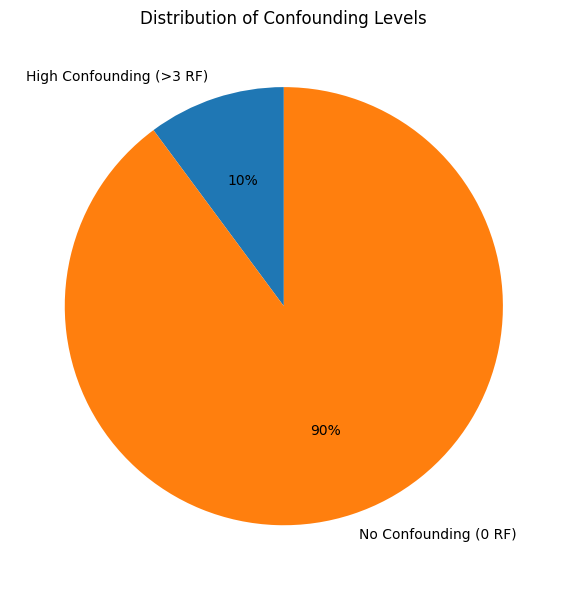

In [84]:
#TO DO on ALL
rf_categories = {
    'High Confounding (>3 RF)': sum(1 for p in full_pair_analyses if p['n_shared'] > 3),
    'Medium Confounding (2-3 RF)': sum(1 for p in full_pair_analyses if 2 <= p['n_shared'] <= 3),
    'Low Confounding (1 RF)': sum(1 for p in full_pair_analyses if p['n_shared'] == 1),
    'No Confounding (0 RF)': sum(1 for p in full_pair_analyses if p['n_shared'] == 0)
}

# Remove zero-count categories
rf_categories = {k: v for k, v in rf_categories.items() if v > 0}

# Plot
if rf_categories:
    plt.figure(figsize=(8, 6))
    plt.pie(rf_categories.values(), labels=rf_categories.keys(), autopct='%1.0f%%', startangle=90)
    plt.title('Distribution of Confounding Levels')
    plt.tight_layout()
    plt.savefig("top_pairs_risk_factor_analysis.svg", format="svg", dpi=300, bbox_inches='tight')
    plt.show()


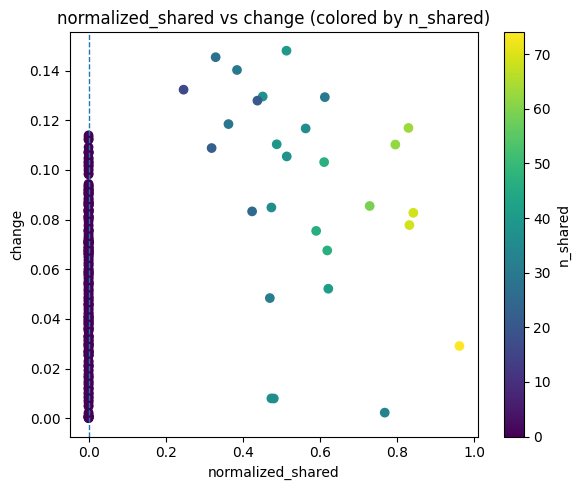

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(full_pair_analyses)

fig, ax = plt.subplots(figsize=(6, 5))

sc = ax.scatter(
    df["normalized_shared"],
    abs(df["change"]),
    c=df["n_shared"],        # color by n_shared
)

ax.set_ylabel("change")
ax.set_xlabel("normalized_shared")
ax.set_title("normalized_shared vs change (colored by n_shared)")
ax.axvline(0, linestyle="--", linewidth=1)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("n_shared")

plt.tight_layout()
plt.show()

In [86]:
df.shape

(276, 6)

In [87]:
df.loc[(df["n_rf_disease1"] == 0) | (df["n_rf_disease2"] == 0), :].shape

(248, 6)

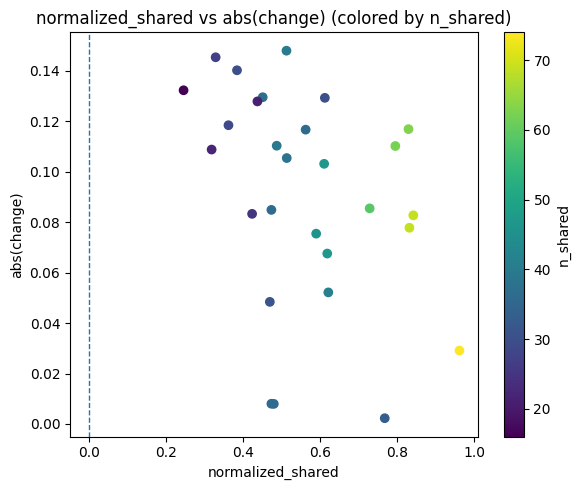

In [88]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(full_pair_analyses)

# keep only rows where both are non-zero
df_filt = df[(df["n_rf_disease1"] != 0) & (df["n_rf_disease2"] != 0)]

fig, ax = plt.subplots(figsize=(6, 5))

sc = ax.scatter(
    df_filt["normalized_shared"],
    df_filt["change"].abs(),
    c=df_filt["n_shared"]
)

ax.set_ylabel("abs(change)")
ax.set_xlabel("normalized_shared")
ax.set_title("normalized_shared vs abs(change) (colored by n_shared)")
ax.axvline(0, linestyle="--", linewidth=1)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("n_shared")

plt.tight_layout()
plt.show()


In [89]:
df_filt

,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared,change
0,Tricuspid Valve Insufficiency ↔ Diabetes Mellitus,75,43,40,0.512821,-0.147997
1,Acute Kidney Injury ↔ Hypertension,76,33,27,0.329268,-0.145393
2,Tricuspid Valve Insufficiency ↔ Hypertension,75,33,30,0.384615,-0.140243
3,"Tachycardia, Ventricular ↔ Hypertension",48,33,16,0.246154,-0.132308
4,Acute Kidney Injury ↔ Diabetes Mellitus,76,43,37,0.451220,-0.129559
5,Mitral Valve Insufficiency ↔ Diabetes Mellitus,36,43,30,0.612245,-0.129309
6,Mitral Valve Insufficiency ↔ Hypertension,36,33,21,0.437500,-0.127894
7,Hypertension ↔ Aortic Valve Stenosis,33,76,29,0.362500,-0.118455
8,Tricuspid Valve Insufficiency ↔ Kidney Disease...,75,64,63,0.828947,-0.116903
9,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",36,64,36,0.562500,-0.116700


In [96]:
print("CORRELATION ANALYSIS OF CHANGE")
print("-" * 25)

# Correlation between original and modified matrices
pearson_r, pearson_p = pearsonr(np.abs(df_filt['change']), df_filt['n_shared'])
spearman_r, spearman_p = spearmanr(np.abs(df_filt['change']), df_filt['n_shared'])

print(f"Pearson correlation: {pearson_r:.4f} (p={pearson_p:.2e})")
print(f"Spearman rank correlation: {spearman_r:.4f} (p={spearman_p:.2e})")

CORRELATION ANALYSIS OF CHANGE
-------------------------
Pearson correlation: -0.2473 (p=2.04e-01)
Spearman rank correlation: -0.3479 (p=6.96e-02)


In [120]:
import numpy as np
from scipy.special import erfc

def fisher_z_diff_test(R1, R2, n, alpha=0.05, clip_eps=1e-7, return_p=True):
    """
    Fisher z-transform difference test between two correlation matrices.

    Parameters
    ----------
    R1, R2 : array-like (p x p)
        Correlation matrices (same shape).
    n : int
        Sample size used to estimate correlations (assumes same n for both).
    alpha : float
        Significance level for the boolean mask.
    clip_eps : float
        Prevents infinities when r is +/-1 by clipping to (-1+eps, 1-eps).
    return_p : bool
        If True, also returns p-values (two-sided).

    Returns
    -------
    Z_diff : np.ndarray (p x p)
        Z scores of differences.
    pvals : np.ndarray (p x p)   (if return_p=True)
        Two-sided p-values.
    sig : np.ndarray (bool) (p x p)
        True where p < alpha (or |Z| > zcrit if p not computed).
    """
    R1 = np.asarray(R1, dtype=float)
    R2 = np.asarray(R2, dtype=float)
    if R1.shape != R2.shape:
        raise ValueError("R1 and R2 must have the same shape.")
    if n <= 3:
        raise ValueError("n must be > 3 for Fisher z standard error.")

    # clip to avoid inf in arctanh for |r|=1
    R1c = np.clip(R1, -1 + clip_eps, 1 - clip_eps)
    R2c = np.clip(R2, -1 + clip_eps, 1 - clip_eps)

    # Fisher z transform (same as 0.5*log((1+r)/(1-r)))
    z1 = np.arctanh(R1c)
    z2 = np.arctanh(R2c)

    # Standard error for difference (same n for both): sqrt( 1/(n-3) + 1/(n-3) )
    se = np.sqrt(2.0 / (n - 3.0))

    Z_diff = (z1 - z2) / se

    # clean diagonal (difference of self-correlation not meaningful)
    np.fill_diagonal(Z_diff, 0.0)

    if not return_p:
        # threshold using normal approx
        zcrit = 1.959963984540054  # ~ qnorm(0.975)
        sig = np.abs(Z_diff) > zcrit
        np.fill_diagonal(sig, False)
        return Z_diff, sig

    # Two-sided p-values without SciPy (uses erfc)
    # p = 2 * (1 - Phi(|Z|)) = erfc(|Z| / sqrt(2))
    pvals = erfc(np.abs(Z_diff) / np.sqrt(2.0))

    np.fill_diagonal(pvals, 1.0)
    sig = pvals < alpha
    np.fill_diagonal(sig, False)

    return Z_diff, pvals, sig


In [121]:
Z_diff, pvals, sig = fisher_z_diff_test(
    similarity_matrix_main,
    similarity_matrix_main_par,
    n=200,   # <-- set this
    alpha=0.05/276
)

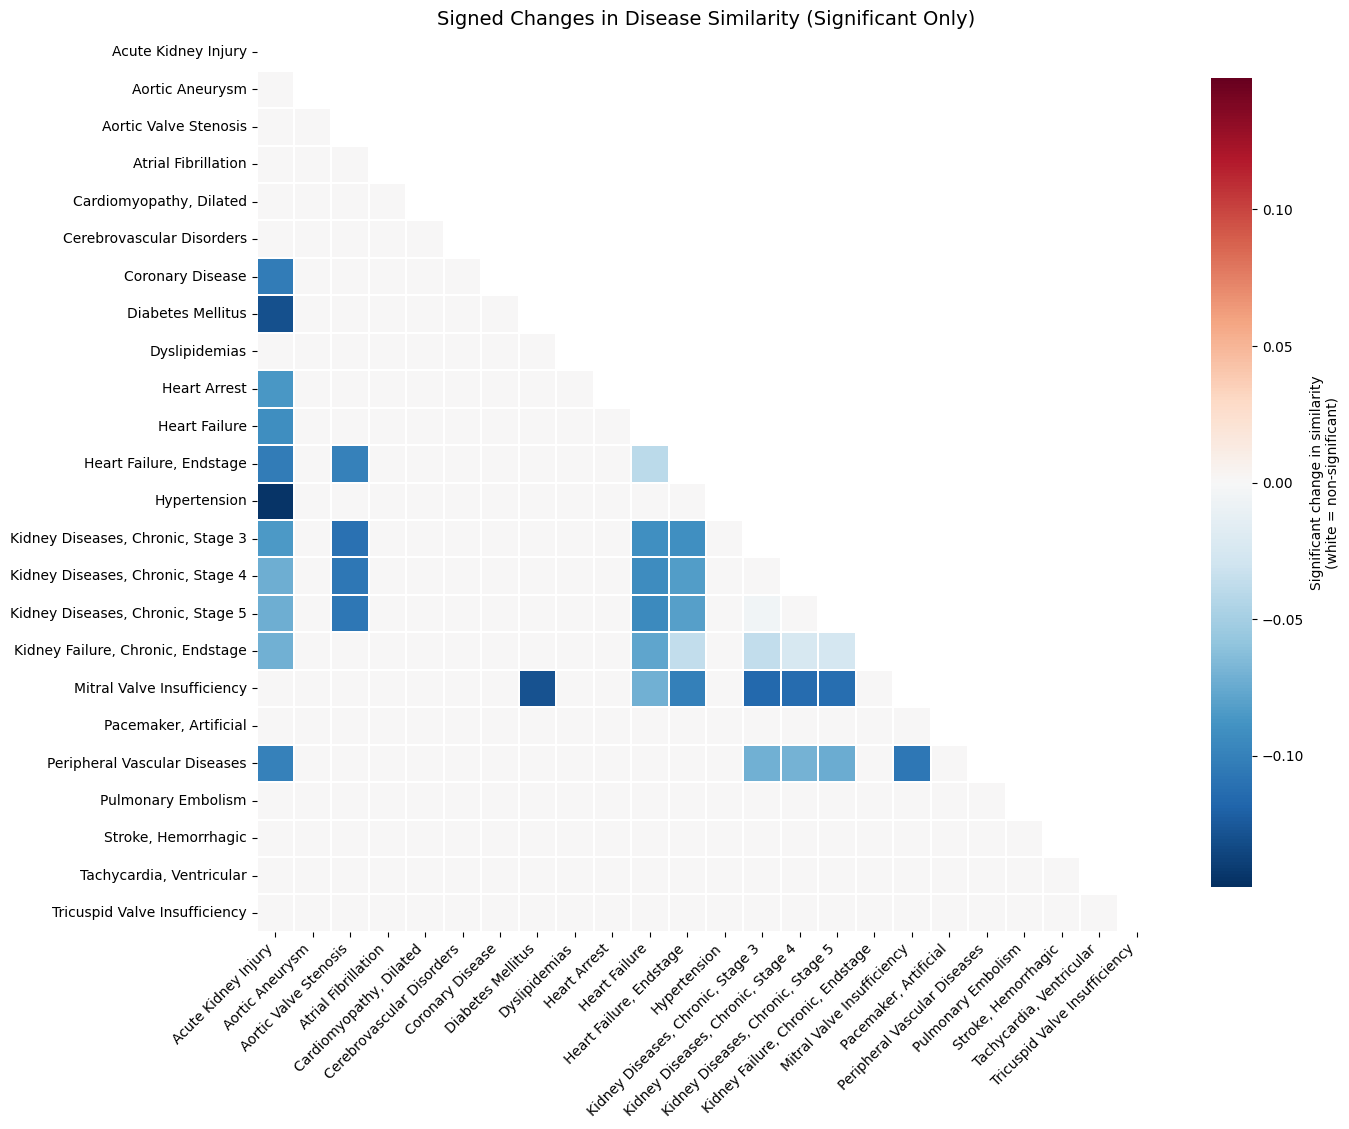

In [122]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# upper triangle + diagonal hidden (show lower only)
mask_tri = np.triu(np.ones(similarity_df_diff_signed.shape, dtype=bool), k=0)

# keep only significant changes; set non-significant to 0 (-> white)
diff_sig = similarity_df_diff_signed.where(sig, other=0)

plt.figure(figsize=(14, 12))
sns.heatmap(
    diff_sig,
    mask=mask_tri,
    cmap="RdBu_r",
    center=0,                 # 0 maps to white
    vmin=-np.nanmax(np.abs(similarity_df_diff_signed.values)),
    vmax= np.nanmax(np.abs(similarity_df_diff_signed.values)),
    annot=False,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Significant change in similarity\n(white = non-significant)"},
    linewidths=0.1
)

plt.title("Signed Changes in Disease Similarity (Significant Only)", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("disease_similarity_changes_signed_sigonly.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()


In [125]:
import pandas as pd

# --- make sure sig is a DataFrame aligned to your disease labels ---
if isinstance(sig, pd.DataFrame):
    sig_df = sig
else:
    sig_df = pd.DataFrame(
        sig,
        index=similarity_df_diff_signed.index,
        columns=similarity_df_diff_signed.columns
    )

def is_significant_pair(d1, d2, sig_df):
    # robust: check both directions
    if (d1 in sig_df.index) and (d2 in sig_df.columns):
        return bool(sig_df.at[d1, d2])
    if (d2 in sig_df.index) and (d1 in sig_df.columns):
        return bool(sig_df.at[d2, d1])
    return False

# --- keep only significant pairs ---
top_affected_pairs_sig = [
    pair for pair in top_affected_pairs
    if is_significant_pair(pair["disease1"], pair["disease2"], sig_df)
]

print(f"Kept {len(top_affected_pairs_sig)} / {len(top_affected_pairs)} significant pairs")

# --- run your analysis ONLY on significant pairs ---
pair_analyses = [
    analyze_pair_shared_risk_factors_min(pair, disease_correlations)
    for pair in top_affected_pairs_sig
]

df_results = pd.DataFrame(pair_analyses)

# keep columns (include 'change' if you want)
df_results = df_results[["pair", "n_rf_disease1", "n_rf_disease2", "n_shared", "normalized_shared", "change"]]

# sort and invert like your original code
df_results_sorted = (
    df_results.sort_values(by="change", ascending=False)
              .iloc[::-1]
              .reset_index(drop=True)
)

df_results_sorted



Kept 38 / 276 significant pairs


,pair,n_rf_disease1,n_rf_disease2,n_shared,normalized_shared,change
0,Acute Kidney Injury ↔ Hypertension,76,33,27,0.818182,-0.145393
1,Acute Kidney Injury ↔ Diabetes Mellitus,76,43,37,0.860465,-0.129559
2,Mitral Valve Insufficiency ↔ Diabetes Mellitus,36,43,30,0.833333,-0.129309
3,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",36,64,36,1.000000,-0.116700
4,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",36,0,0,0.000000,-0.113921
5,"Mitral Valve Insufficiency ↔ Kidney Diseases, ...",36,0,0,0.000000,-0.113143
6,"Aortic Valve Stenosis ↔ Kidney Diseases, Chron...",76,64,62,0.968750,-0.110209
7,"Kidney Diseases, Chronic, Stage 4 ↔ Aortic Val...",0,76,0,0.000000,-0.107011
8,Mitral Valve Insufficiency ↔ Peripheral Vascul...,36,0,0,0.000000,-0.106901
9,"Aortic Valve Stenosis ↔ Kidney Diseases, Chron...",76,0,0,0.000000,-0.106874
